In [5]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import os

mpl.rcdefaults()
mpl.rcParams.update({
    'text.usetex':         True,
    'font.family':         'serif',
    'font.serif':          ['Computer Modern Roman'],
    'font.size':           10,
    'axes.labelsize':      11,
    'axes.titlesize':      11,
    'xtick.labelsize':     9,
    'ytick.labelsize':     9,
    'legend.fontsize':     8,
    'xtick.direction':     'in',
    'ytick.direction':     'in',
    'xtick.top':           True,
    'ytick.right':         True,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'xtick.major.size':    4,
    'xtick.minor.size':    2,
    'ytick.major.size':    4,
    'ytick.minor.size':    2,
    'lines.linewidth':     1.5,
    'lines.markersize':    4.5,
    'axes.linewidth':      0.8,
    'axes.grid':           True,
    'grid.alpha':          0.25,
    'grid.linewidth':      0.5,
    'figure.dpi':          150,
    'savefig.dpi':         300,
    'savefig.bbox':        'tight',
})

COLORS_N = ['#0072B2', '#E69F00', '#009E73', '#D55E00']   # by n_I
COLORS_P = ['#0072B2', '#E69F00', '#009E73', '#D55E00']   # by p
COLORS_A = ['#999999', '#56B4E9', '#E69F00', '#CC79A7']   # by spin
MARKERS  = ['o', 's', '^', 'D']

# observables in each dataset
OBS_SHARED = {
    'd':    {'label': r'$d$ ($\mu$as)',         'pi': False, 'band': None},
    'w':    {'label': r'$w$ ($\mu$as)',         'pi': False, 'band': None},
    'Asym': {'label': r'Asymmetry $A$',         'pi': False, 'band': None},
    'eta':  {'label': r'$\eta$ (rad)',           'pi': True,  'band': None},
}

OBS_POLAR_ONLY = {
    'argbeta2': {'label': r'$\angle\beta_2$ (rad)', 'pi': True},
}

all_obs = {**OBS_SHARED, **OBS_POLAR_ONLY}

out_dir = "/Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis"
df_pol  = pd.read_csv(os.path.join(out_dir, "params_polar.csv"))
df_nop  = pd.read_csv(os.path.join(out_dir, "params_nopolar.csv"))

pvals  = [0.0, 0.5, 0.75, 1.0]
nvals  = [0.0, 0.5, 1.0,  1.5]
a_vals = [0.01, 0.25, 0.5, 0.75, 0.9, 0.998]

fig_dir = out_dir

def pi_formatter(ax, scale=4):
    ax.yaxis.set_major_locator(ticker.MultipleLocator(np.pi / scale))
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, _: rf'${x/np.pi:.2g}\pi$'))

def save_fig(fig, name):
    out = os.path.join(fig_dir, name)
    fig.savefig(out)
    print(f"Saved: {out}")

def make_legend(ax, df_pol=True):
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles, labels, framealpha=0.9, edgecolor='none',
              ncol=1, handlelength=1.5)

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_spin_by_p_pol.png


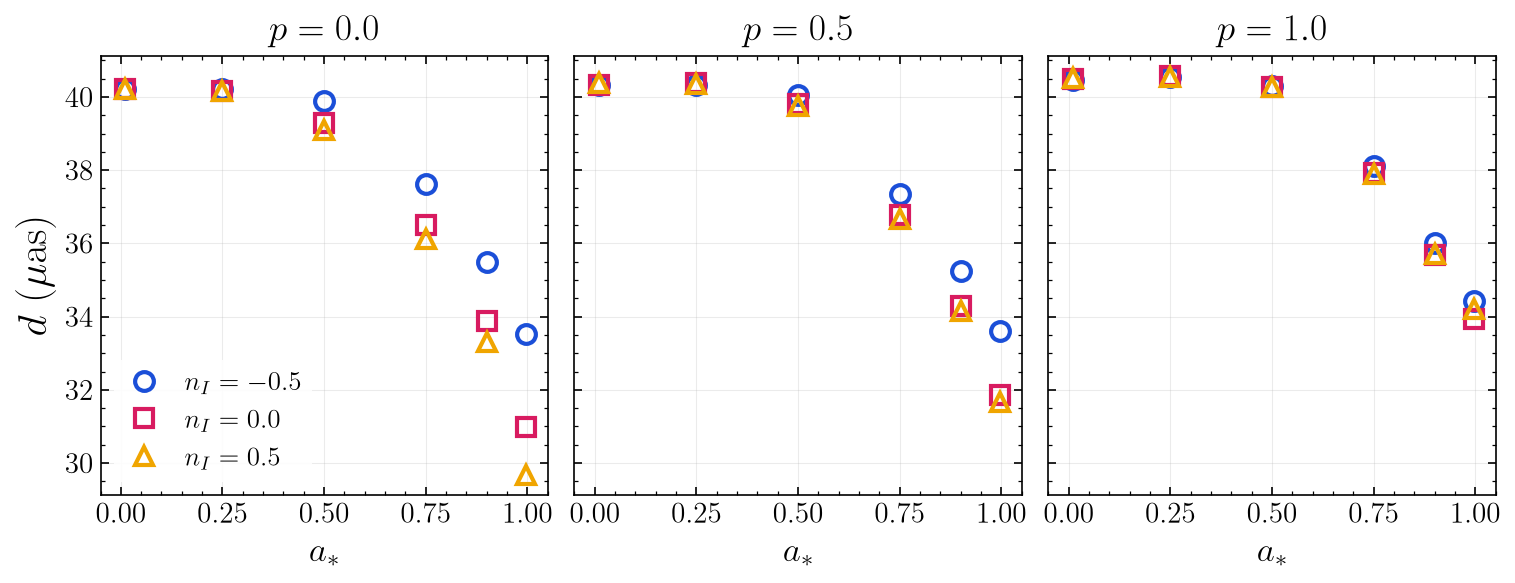

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_spin_by_p_nopol.png


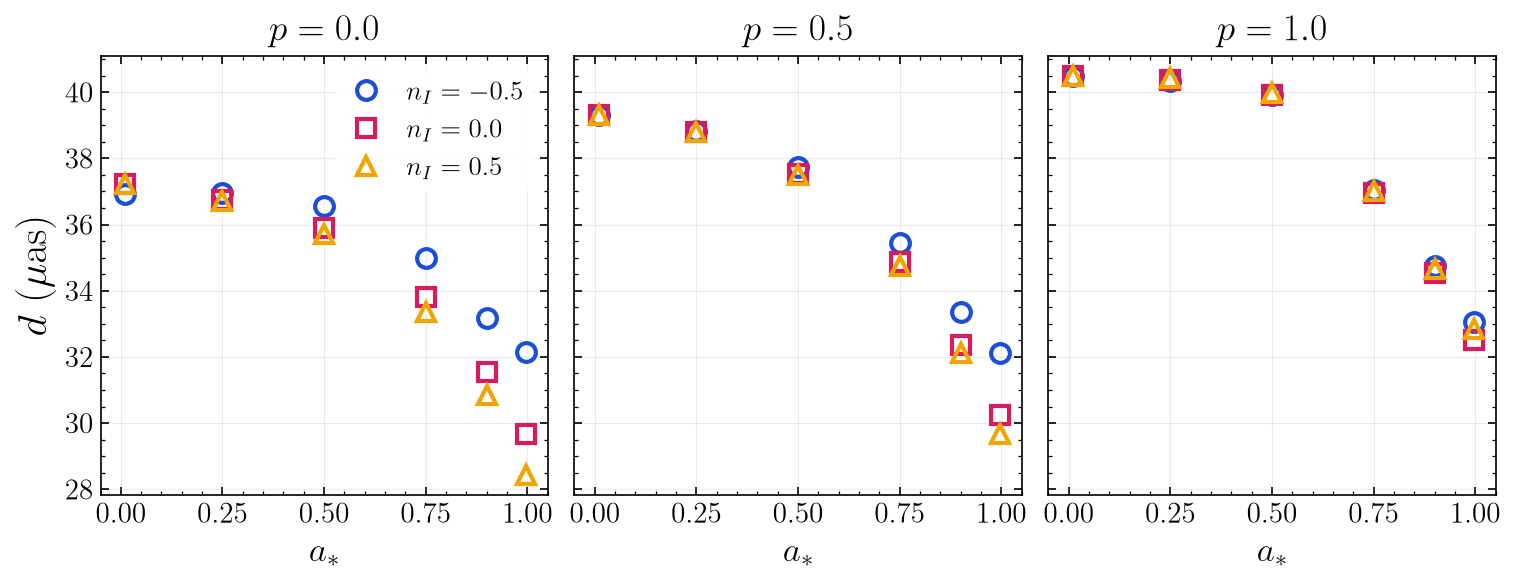

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_spin_by_p_pol.png


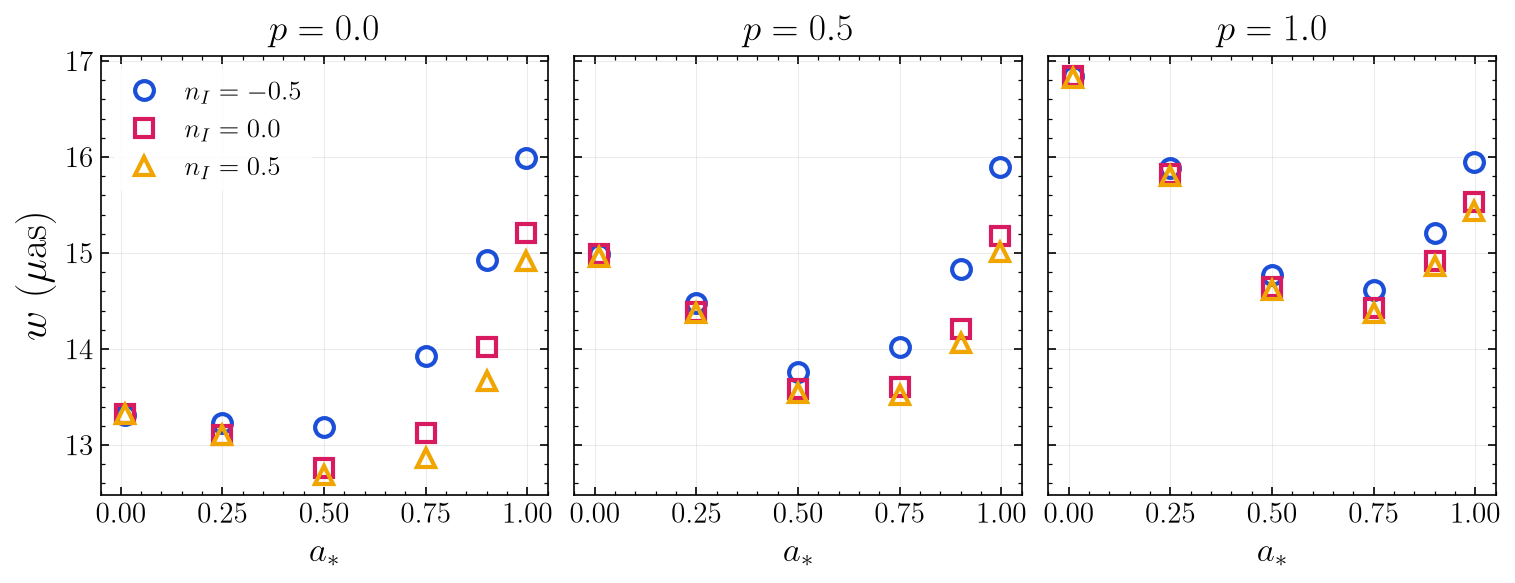

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_spin_by_p_nopol.png


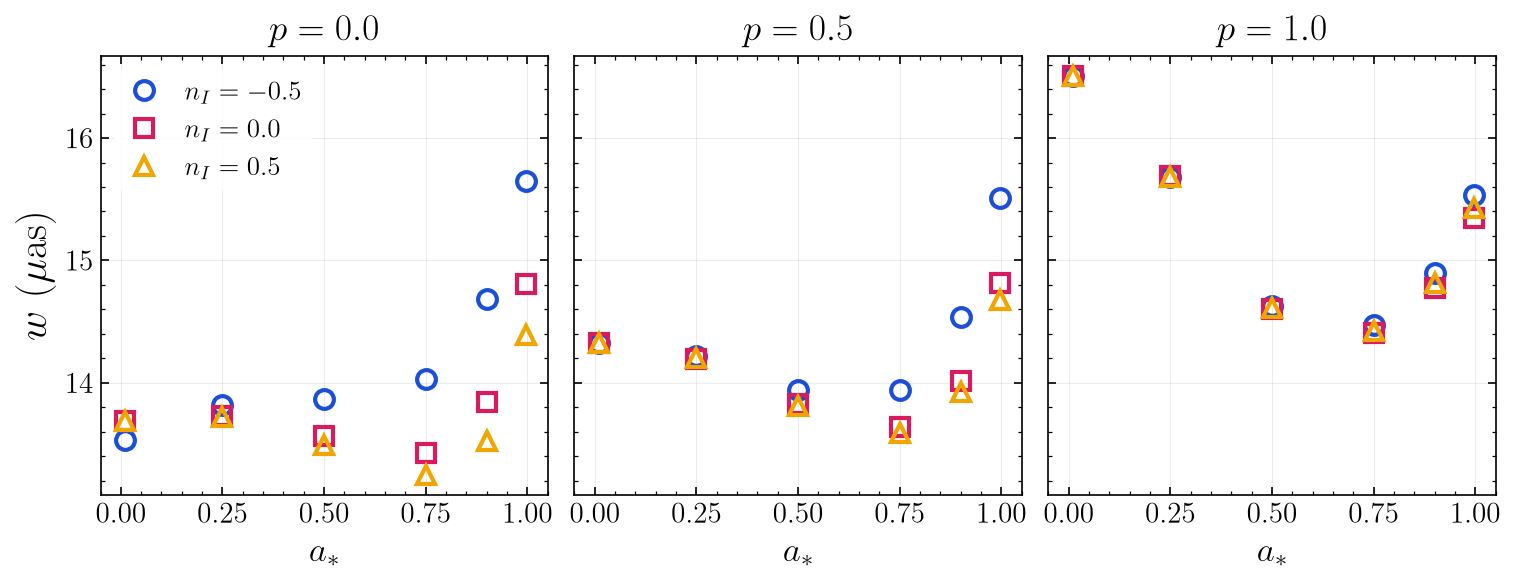

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_spin_by_p_pol.png


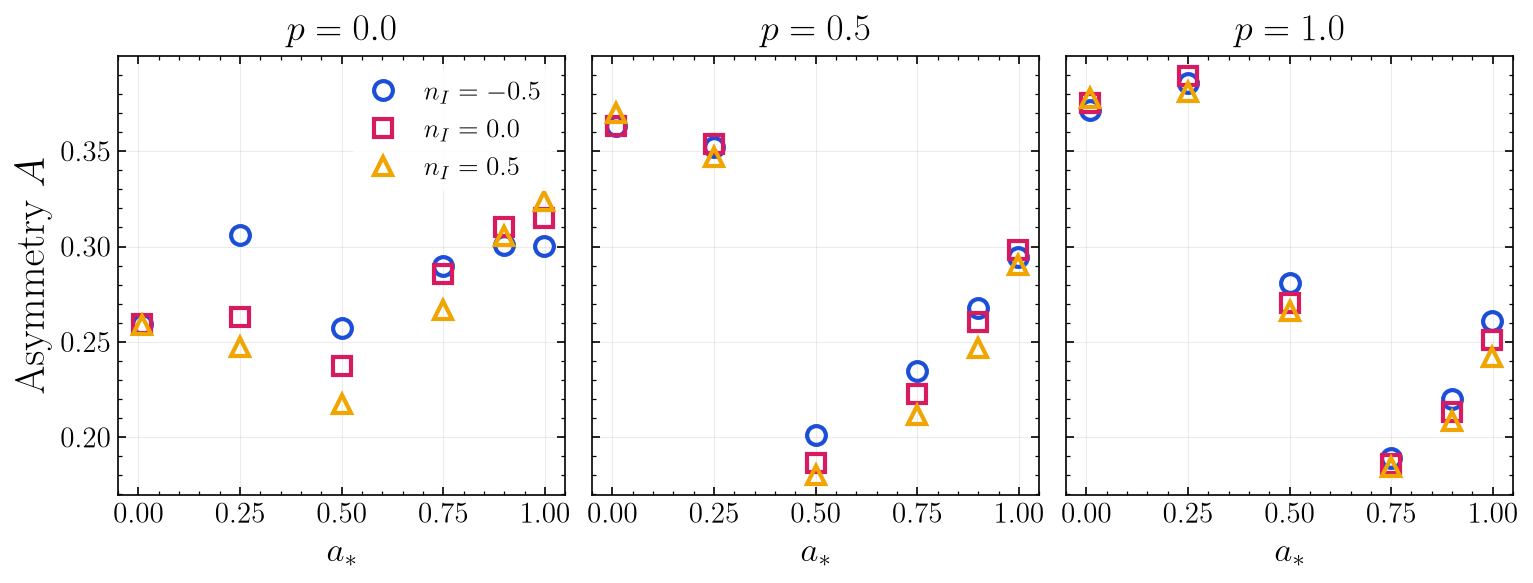

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_spin_by_p_nopol.png


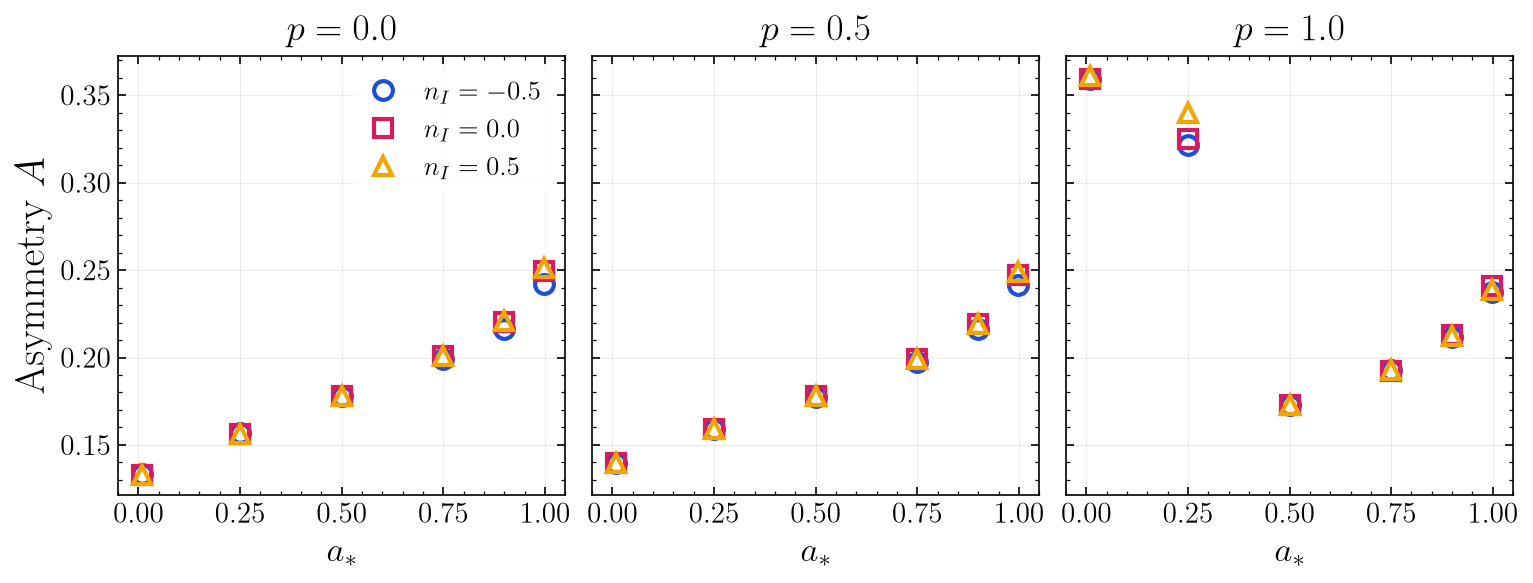

argbeta2  pol    raw span 1.991pi  ->  wrapped 1.064pi
Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_spin_by_p_pol.png


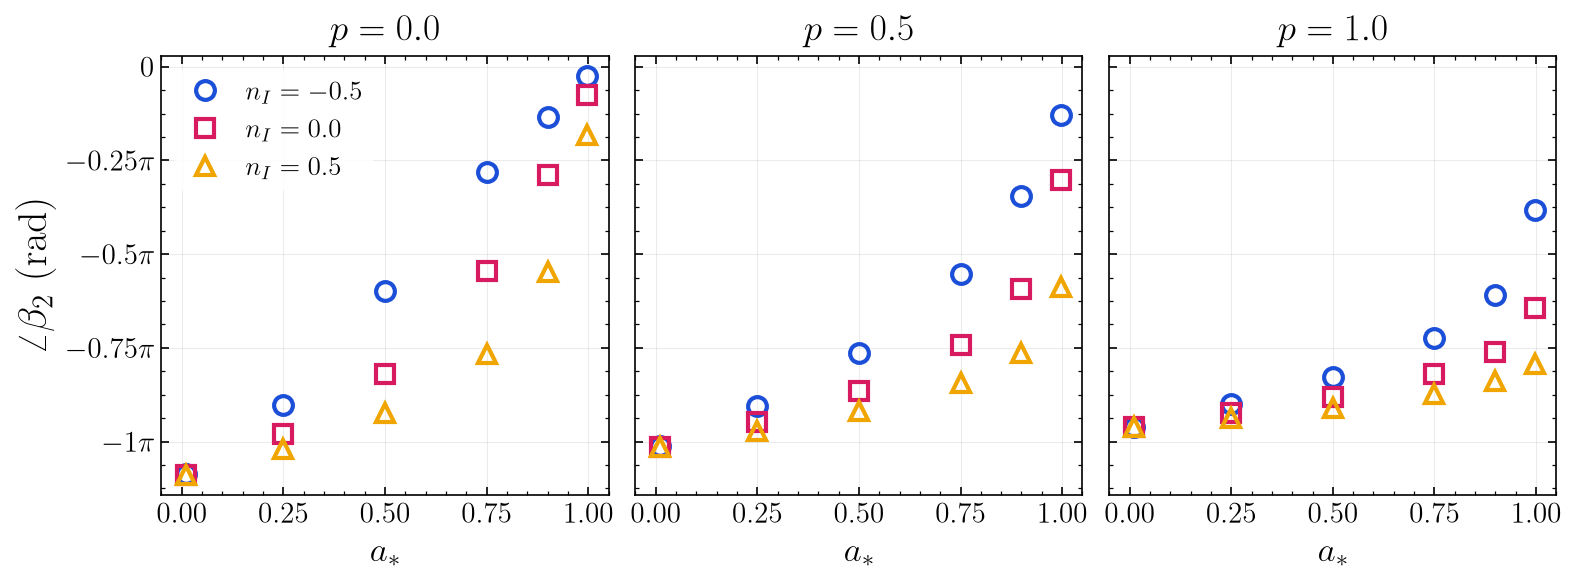

eta       pol    raw span 0.245pi  ->  wrapped 0.232pi
Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_spin_by_p_pol.png


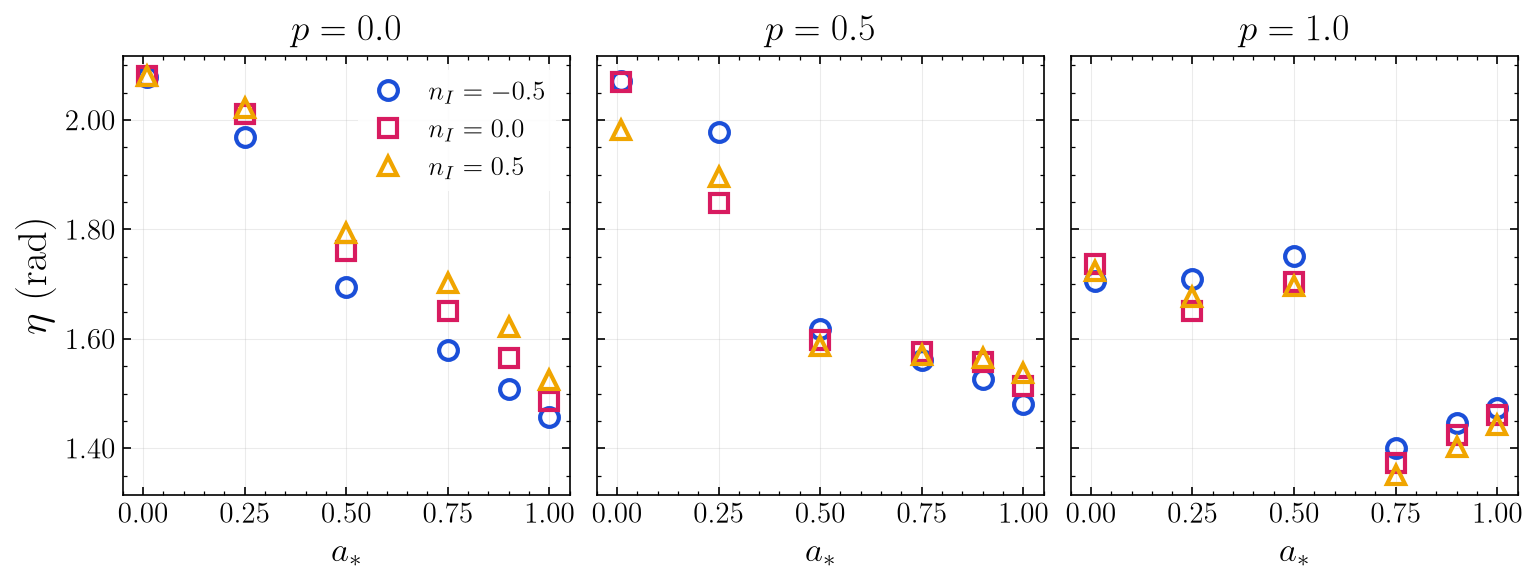

eta       nopol  raw span 0.191pi  ->  wrapped 0.144pi
Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_spin_by_p_nopol.png


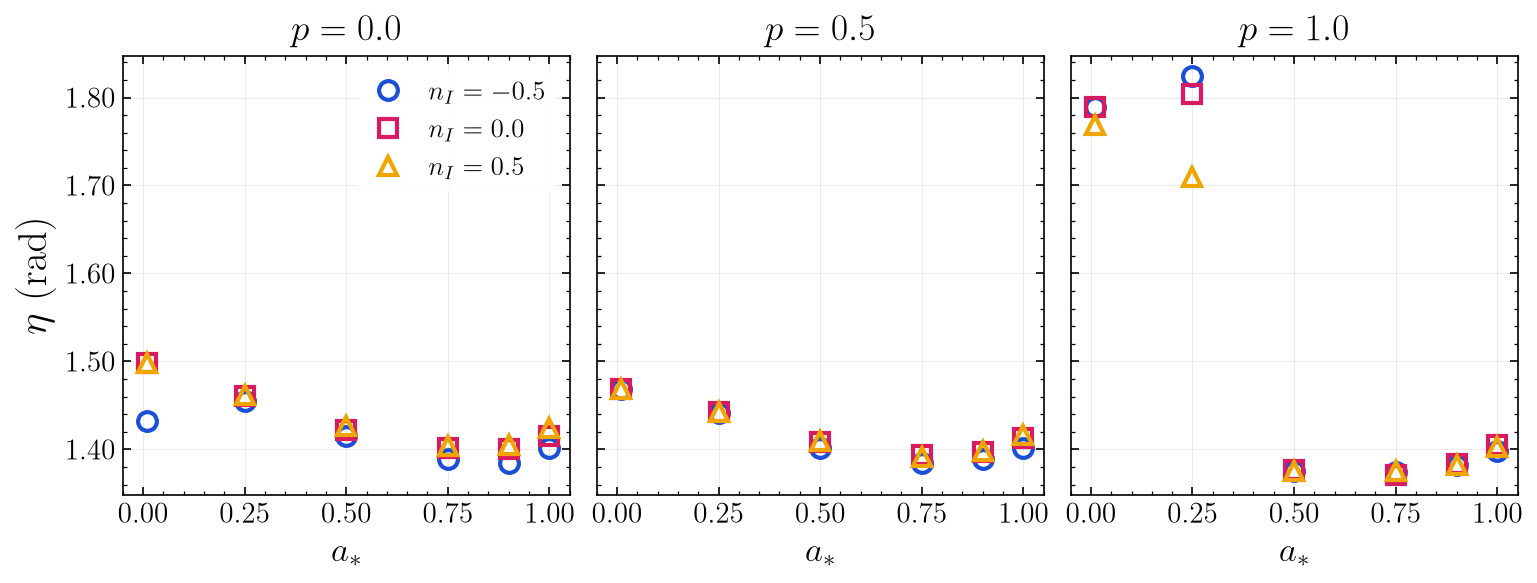

In [6]:
# plot type 3 — one figure per observable (and per sin(theta_B) variant)
# columns = p, markers = n_I, x = spin, no connecting lines

obs_rows = ['d', 'w', 'Asym', 'argbeta2', 'eta']
p_cols = [0.0, 0.5, 1.0]
ni_lines = [-0.5, 0.0, 0.5]

colors_ni = {-0.5: '#1b4fd8', 0.0: '#d81b60', 0.5: '#f0a500'}
markers_ni = {-0.5: 'o', 0.0: 's', 0.5: '^'}


def branch_top_from(vals):
    """Put the 2pi cut opposite the circular mean, so a cluster is never split."""
    v = np.asarray(vals, float).ravel()
    v = v[np.isfinite(v)]
    if v.size == 0:
        return np.pi
    return np.angle(np.mean(np.exp(1j*v))) + np.pi


def to_branch(x, top):
    return (np.asarray(x, float) - top) % (2*np.pi) - 2*np.pi + top


def pi_formatter(ax, lo, hi, min_ticks=4):
    """pi-fraction ticks for wide angular ranges, plain radians for narrow ones."""
    span = max(hi - lo, 1e-12)
    if span < 0.75*np.pi:
        ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(5))
        ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter('%.2f'))
        return
    for den in (1, 2, 4, 8):
        step = np.pi/den
        if span/step >= min_ticks:
            break
    ax.yaxis.set_major_locator(mpl.ticker.MultipleLocator(step))
    ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(
        lambda v, _: r'$0$' if abs(v) < 1e-12 else rf'${v/np.pi:g}\pi$'))


for obs in obs_rows:
    meta = all_obs[obs]

    variants = [('pol', df_pol, r'with $\sin\theta_B$ dependence')]
    if obs in OBS_SHARED and obs in df_nop.columns:
        variants.append(('nopol', df_nop, r'without $\sin\theta_B$ dependence'))

    for tag, frame, vlabel in variants:

        # one branch for the whole figure, from all of this observable's values
        top = branch_top_from(frame[obs].values) if meta['pi'] else None

        plt.close('all')
        fig, axes = plt.subplots(1, len(p_cols),
                                 figsize=(4.0 * len(p_cols), 3.8),
                                 sharex=True, sharey=True)
        axes = np.atleast_1d(axes)

        plotted = []

        for c, p in enumerate(p_cols):
            ax = axes[c]
            for n_i in ni_lines:
                d = frame[(frame['n_I'] == n_i) &
                          (frame['p_val'] == p)].sort_values('spin')
                if d.empty or obs not in d.columns:
                    continue
                y = d[obs].values
                if meta['pi']:
                    y = to_branch(y, top)
                plotted.append(np.asarray(y, float))
                ax.plot(d['spin'], y, ls='none',
                        marker=markers_ni[n_i], ms=9,
                        mfc='none', mec=colors_ni[n_i], mew=2.0)

            ax.set_xlim(-0.05, 1.05)
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.set_xlabel(r'$a_*$', fontsize=17)
            ax.tick_params(labelsize=14)

            ax.text(0.5, 1.02, rf'$p = {p}$', transform=ax.transAxes,
                    fontsize=18, va='bottom', ha='center')

        # tick formatting needs the data range, so do it after plotting
        if meta['pi'] and plotted:
            allv = np.concatenate(plotted)
            for ax in axes:
                pi_formatter(ax, float(allv.min()), float(allv.max()))
            raw = np.asarray(frame[obs].values, float)
            print(f"{obs:9s} {tag:5s}  raw span {np.ptp(raw)/np.pi:.3f}pi"
                  f"  ->  wrapped {np.ptp(allv)/np.pi:.3f}pi")

        axes[0].set_ylabel(meta['label'], fontsize=20)

        ni_handles = [Line2D([], [], ls='none', marker=markers_ni[n],
                             ms=9, mfc='none', mec=colors_ni[n], mew=2.0,
                             label=rf'$n_I = {n}$')
                      for n in ni_lines]
        axes[0].legend(handles=ni_handles, fontsize=13, framealpha=0.9,
                       edgecolor='none', loc='best', handlelength=1.4)

        fig.subplots_adjust(wspace=0.06)
        save_fig(fig, f'{obs}_vs_spin_by_p_{tag}.png')
        plt.show()

In [4]:
# plot type 3 — one figure per observable (and per sin(theta_B) variant)
# columns = p, markers = n_I, x = spin, no connecting lines

obs_rows = ['d', 'w', 'Asym', 'argbeta2', 'eta']
p_cols = [0.0, 0.5, 1.0]
ni_lines = [-0.5, 0.0, 0.5]

colors_ni = {-0.5: '#1b4fd8', 0.0: '#d81b60', 0.5: '#f0a500'}
markers_ni = {-0.5: 'o', 0.0: 's', 0.5: '^'}

branch_top = np.pi / 2

def branch_top_from(vals):
    """Put the 2pi cut opposite the circular mean, so a cluster is never split."""
    v = np.asarray(vals, float).ravel()
    v = v[np.isfinite(v)]
    if v.size == 0:
        return np.pi
    return np.angle(np.mean(np.exp(1j*v))) + np.pi


def to_branch(x, top):
    return (np.asarray(x, float) - top) % (2*np.pi) - 2*np.pi + top

def wrap_angle(x, top=branch_top):
    return (np.asarray(x, dtype=float) - top) % (2 * np.pi) - 2 * np.pi + top


for obs in obs_rows:
    meta = all_obs[obs]
    ...
    for tag, frame, vlabel in variants:

        top = branch_top_from(frame[obs].values) if meta['pi'] else None   # <-- add

        plt.close('all')
        fig, axes = plt.subplots(...)

        for c, p in enumerate(p_cols):
            ax = axes[c]
            for n_i in ni_lines:
                d = frame[(frame['n_I'] == n_i) & (frame['p_val'] == p)].sort_values('spin')
                if d.empty or obs not in d.columns:
                    continue
                y = d[obs].values
                if meta['pi']:
                    y = to_branch(y, top)       
                ax.plot(d['spin'], y, ls='none',
                        marker=markers_ni[n_i], ms=9,
                        mfc='none', mec=colors_ni[n_i], mew=2.0)

            ax.set_xlim(-0.05, 1.05)
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.set_xlabel(r'$a_*$', fontsize=17)
            ax.tick_params(labelsize=14)

            if meta['pi']:
                pi_formatter(ax, scale=4)

            ax.text(0.5, 1.02, rf'$p = {p}$', transform=ax.transAxes,
                    fontsize=18, va='bottom', ha='center')

        axes[0].set_ylabel(meta['label'], fontsize=20)

        #if len(variants) > 1:
            #axes[-1].text(0.97, 0.04, vlabel, transform=axes[-1].transAxes,
                          #fontsize=13, va='bottom', ha='right')

        ni_handles = [Line2D([], [], ls='none', marker=markers_ni[n],
                             ms=9, mfc='none', mec=colors_ni[n], mew=2.0,
                             label=rf'$n_I = {n}$')
                      for n in ni_lines]
        axes[0].legend(handles=ni_handles, fontsize=13, framealpha=0.9,
                       edgecolor='none', loc='best', handlelength=1.4)

        fig.subplots_adjust(wspace=0.06)
        save_fig(fig, f'{obs}_vs_spin_by_p_{tag}.png')
        plt.show()

ValueError: Number of rows must be a positive integer, not Ellipsis

<Figure size 960x720 with 0 Axes>

In [3]:
import shutil, os
print(shutil.which('latex'))
print(shutil.which('dvipng'))
print(os.environ['PATH'])

None
None
/Users/kaylacarmical/Documents/JP1/Code/jp1env/bin:/usr/local/bin:/System/Cryptexes/App/usr/bin:/usr/bin:/bin:/usr/sbin:/sbin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/local/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/bin:/var/run/com.apple.security.cryptexd/codex.system/bootstrap/usr/appleinternal/bin:/pkg/env/global/bin


Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_nI_by_spin_polar.png


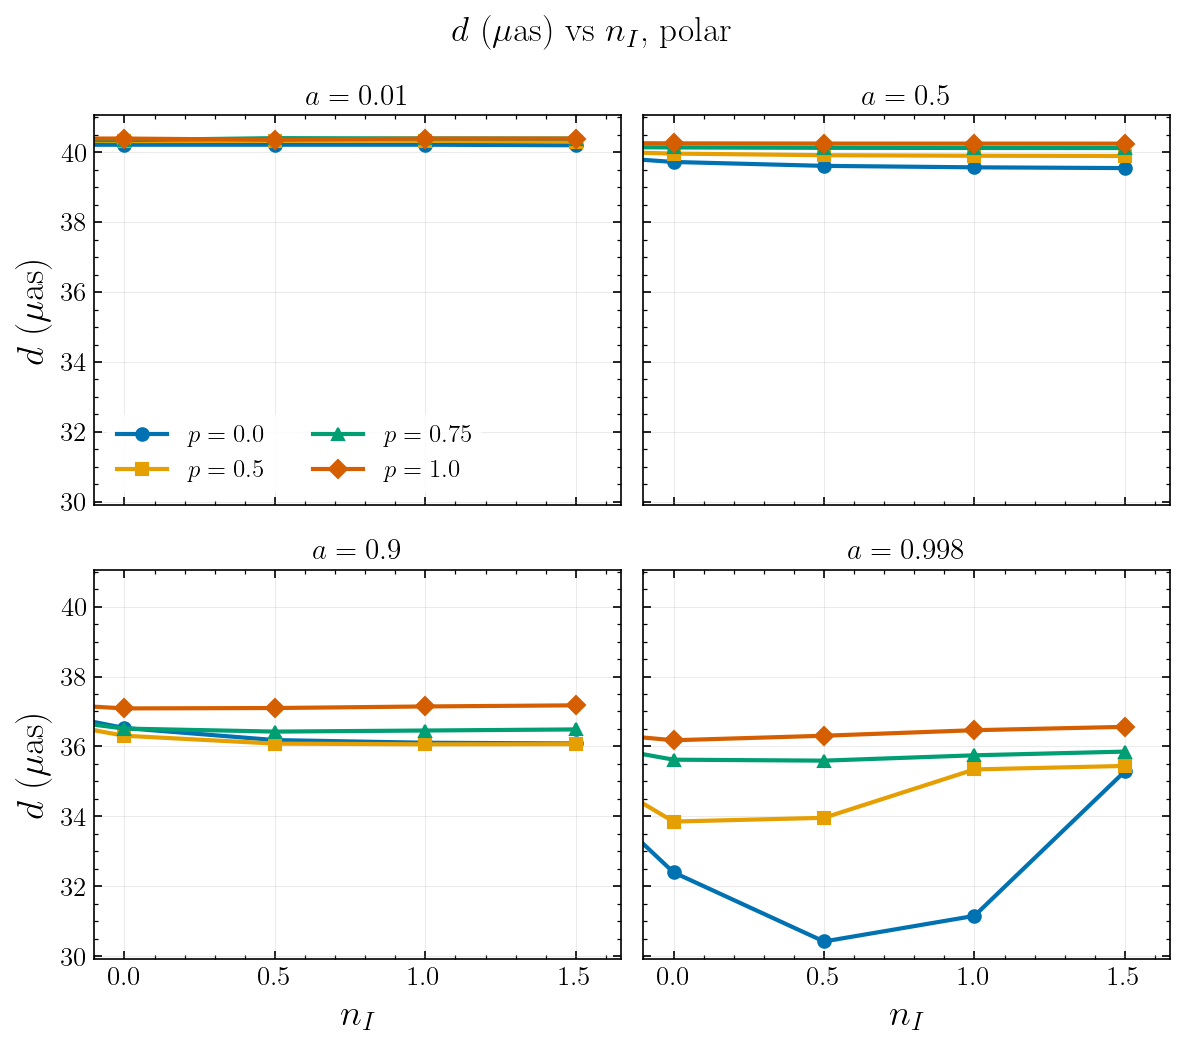

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_nI_by_spin_nopolar.png


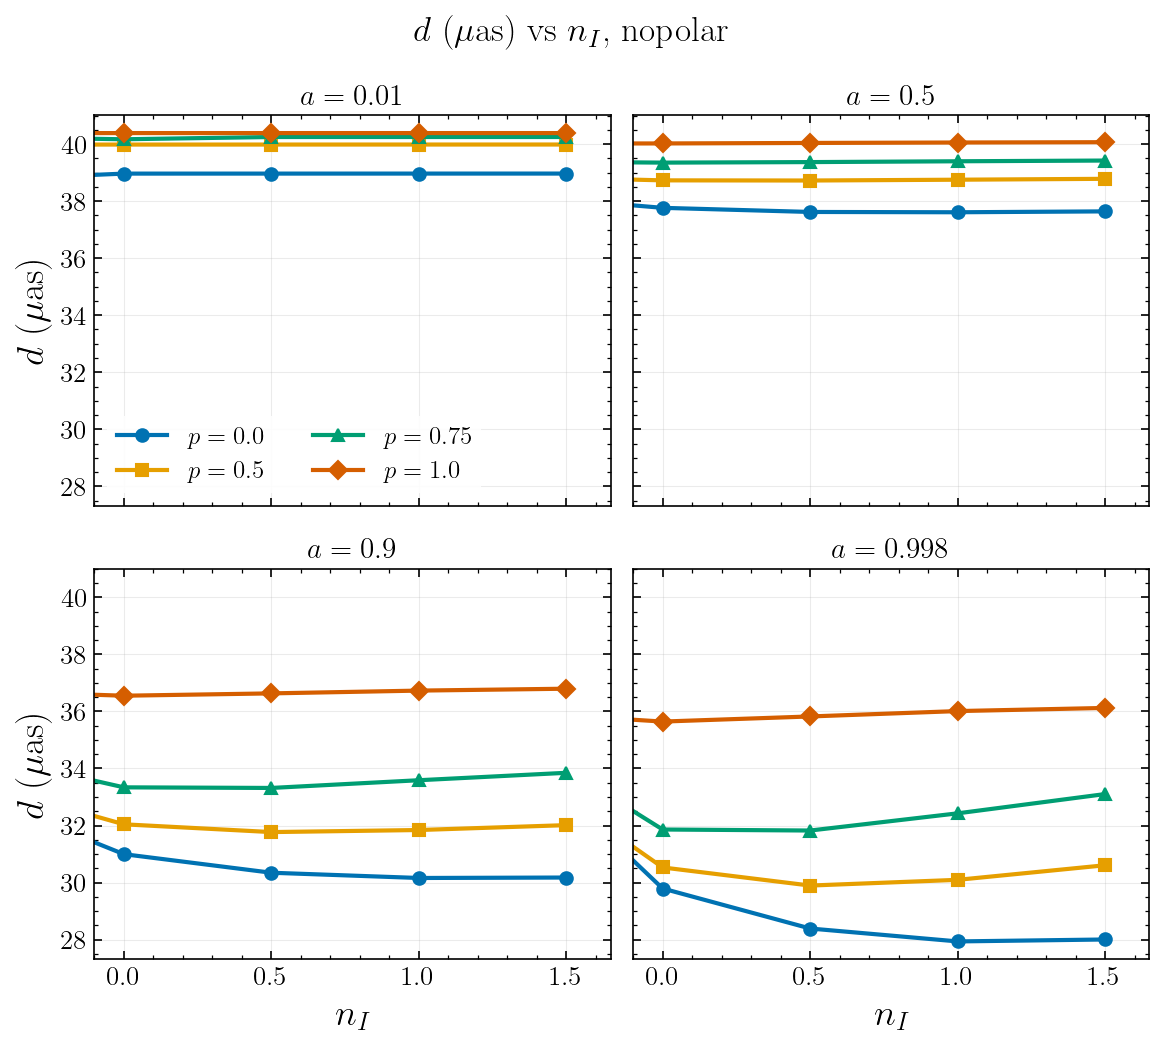

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_nI_by_spin_polar.png


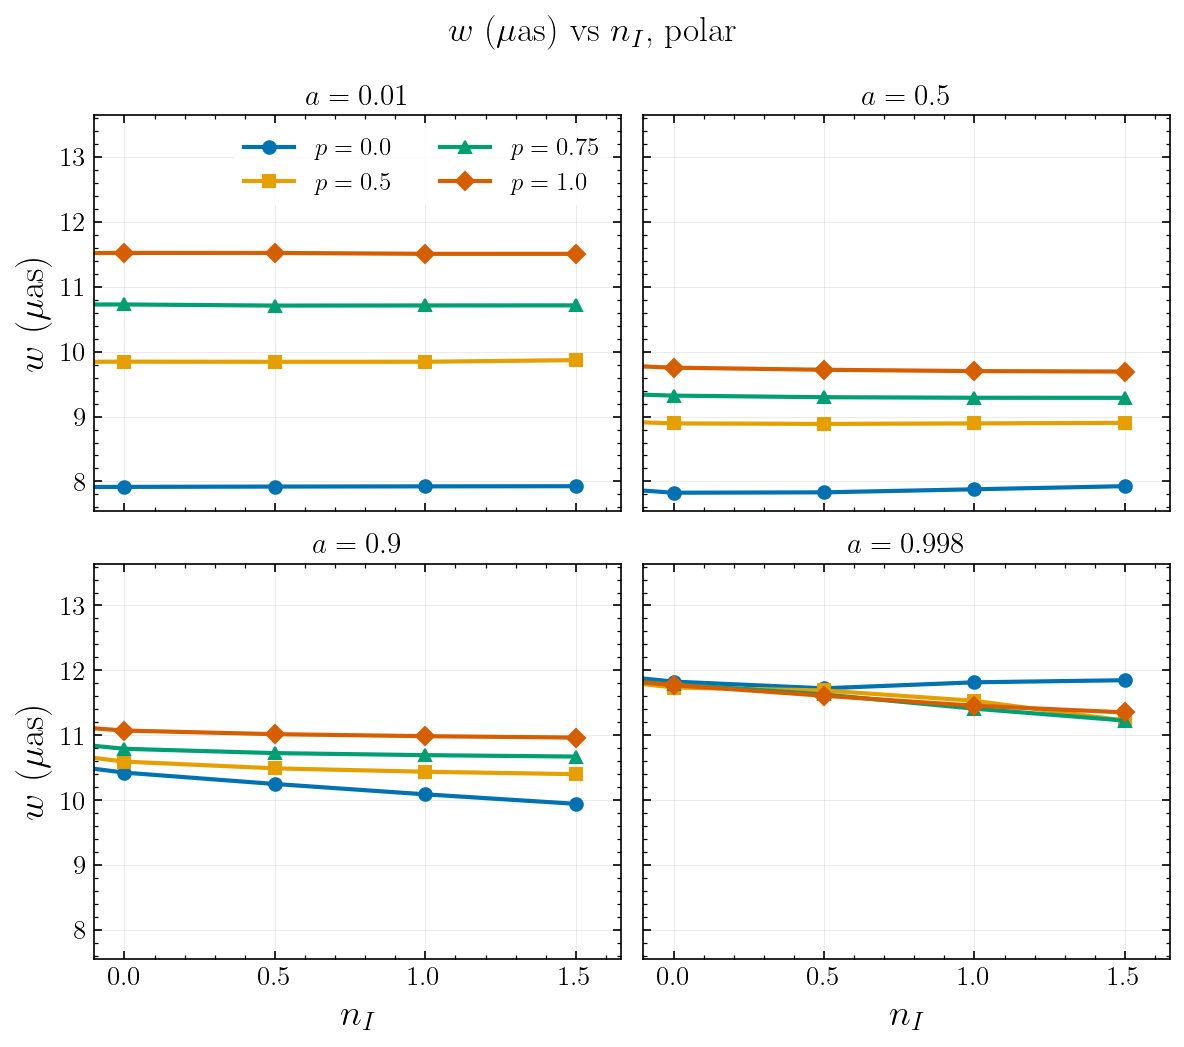

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_nI_by_spin_nopolar.png


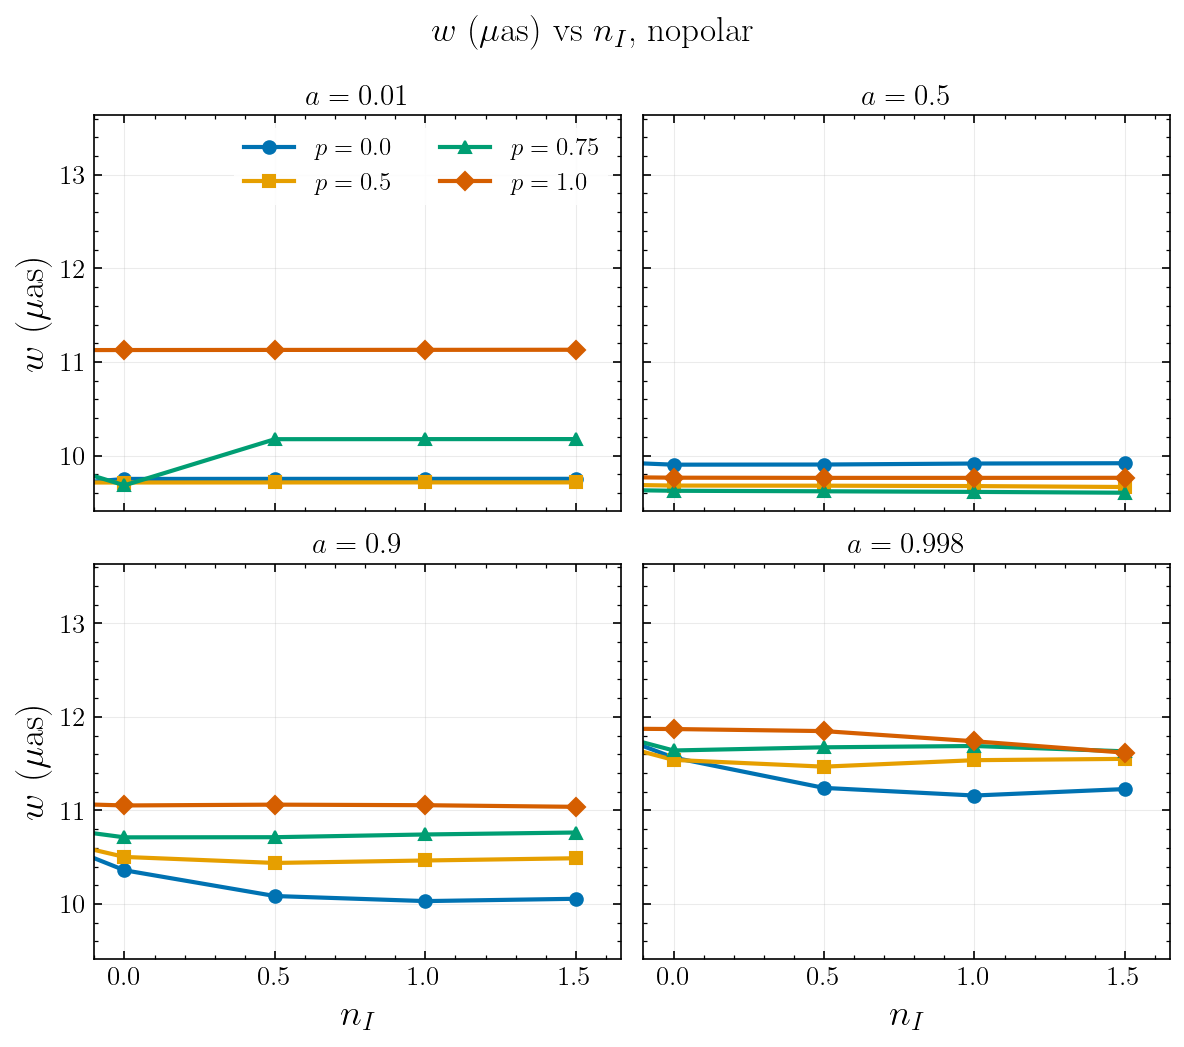

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_nI_by_spin_polar.png


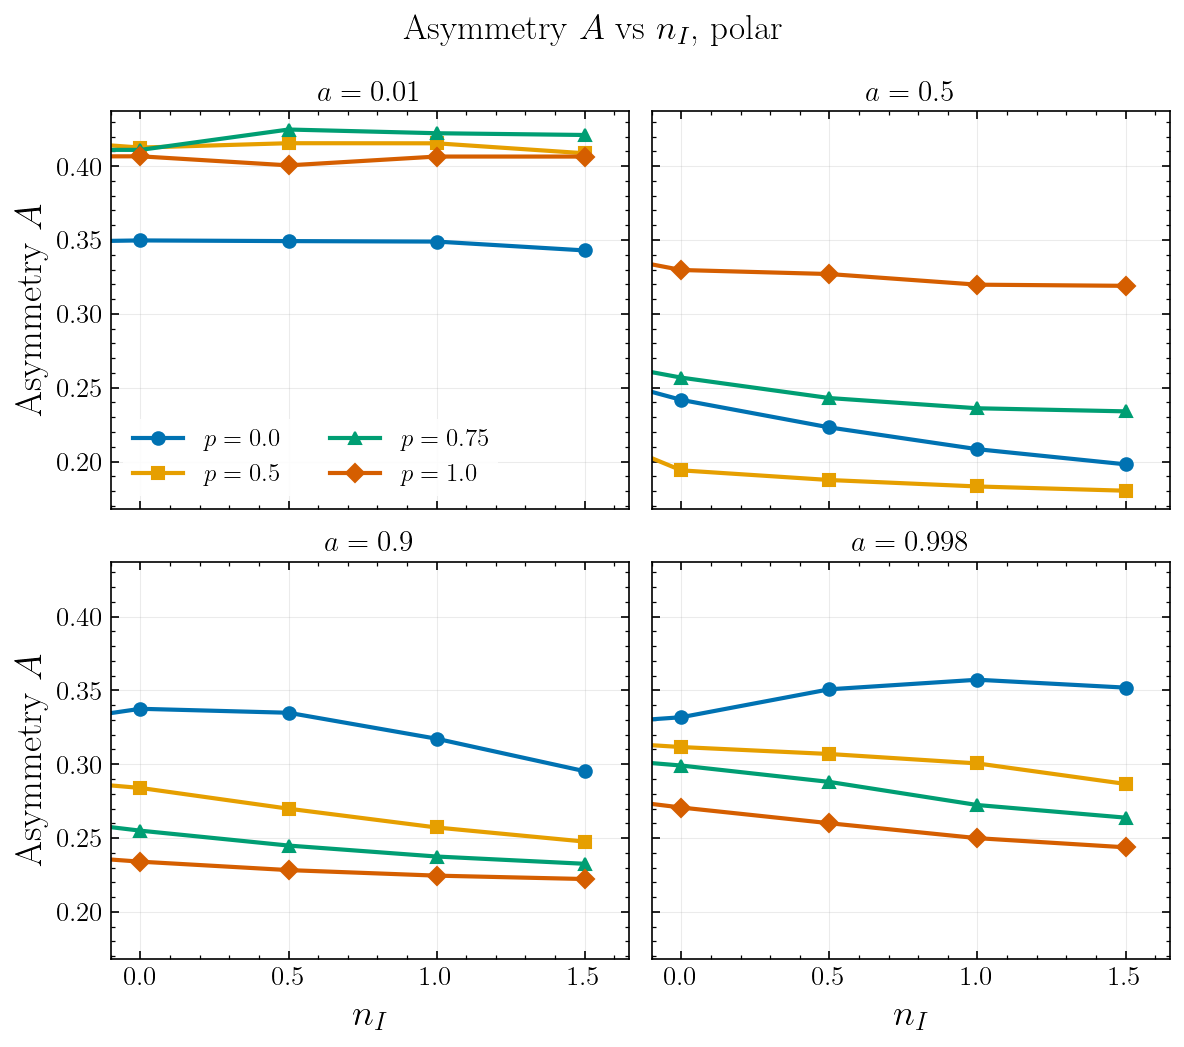

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_nI_by_spin_nopolar.png


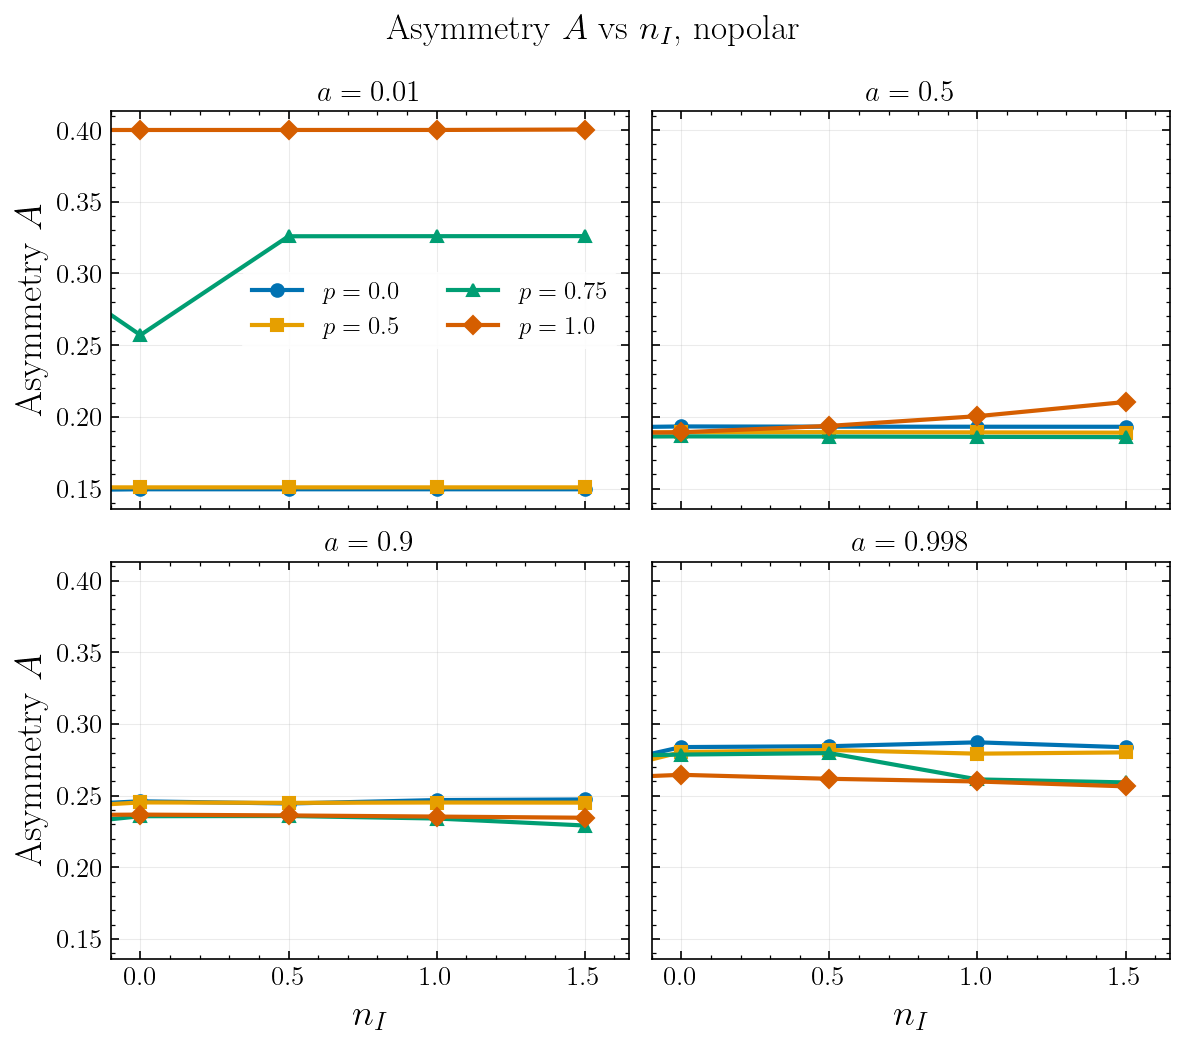

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_nI_by_spin_polar.png


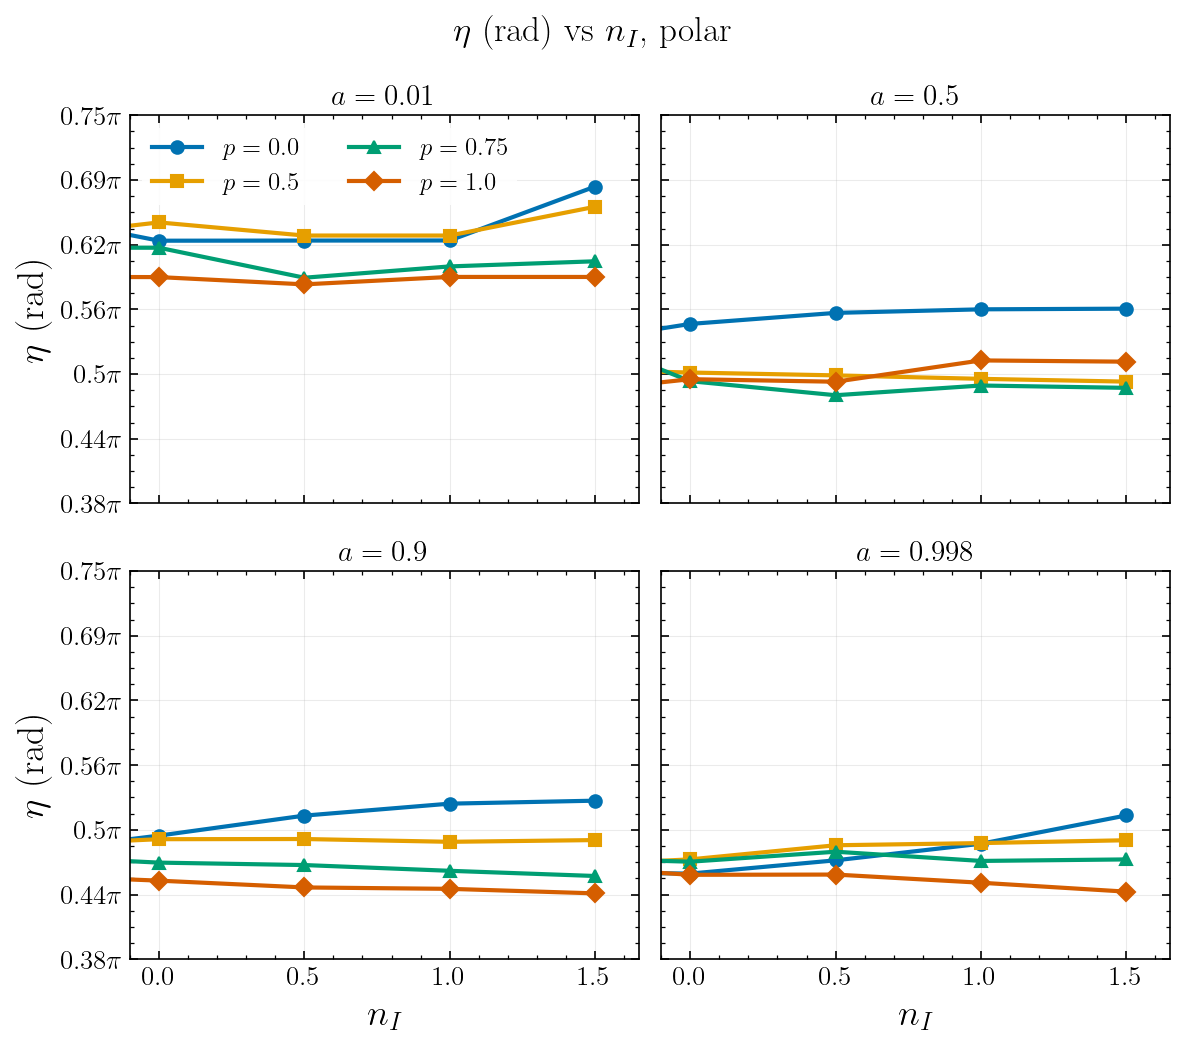

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_nI_by_spin_nopolar.png


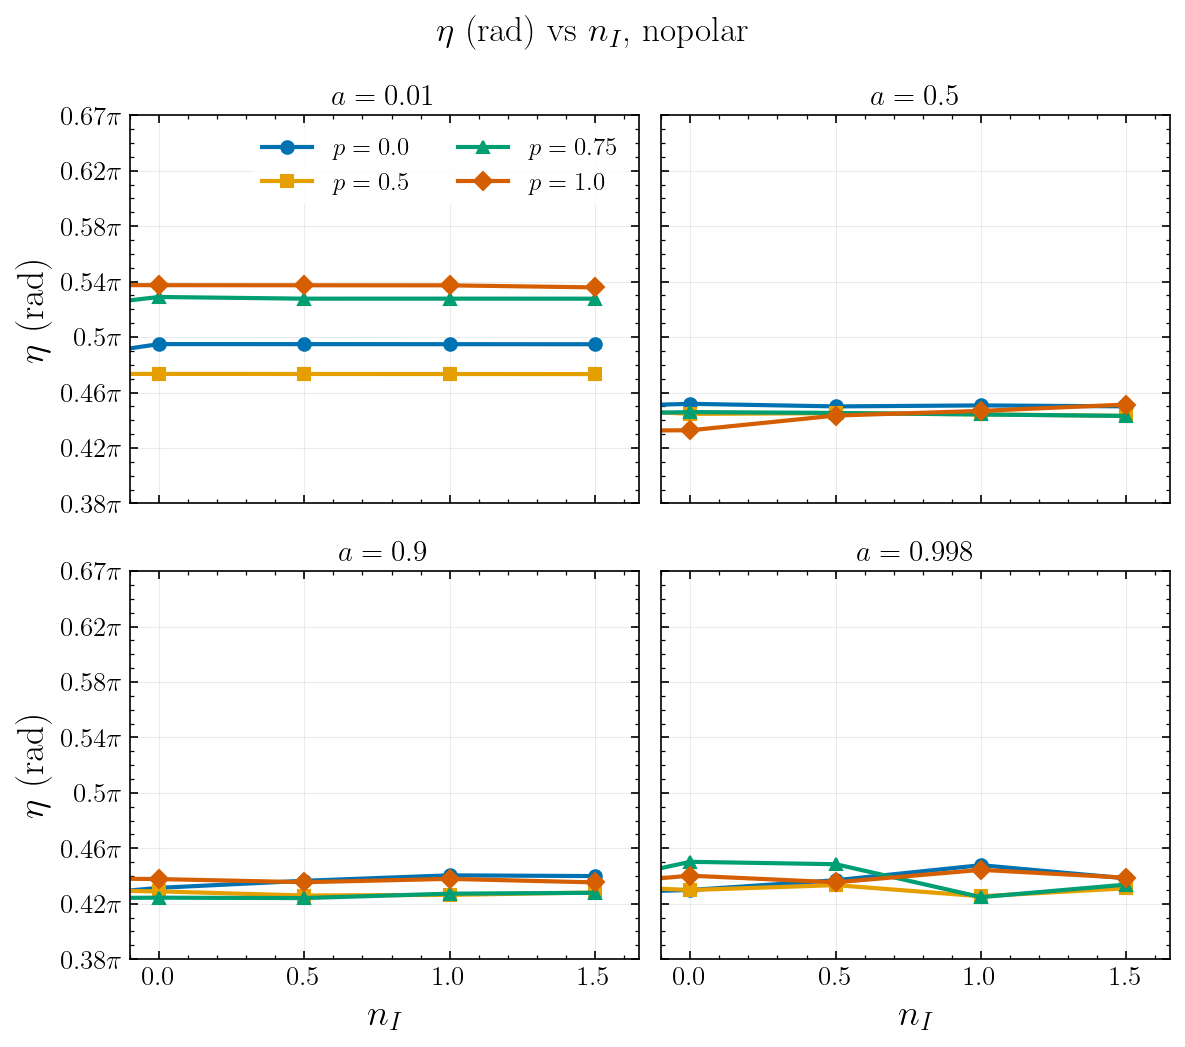

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_nI_by_spin_polar.png


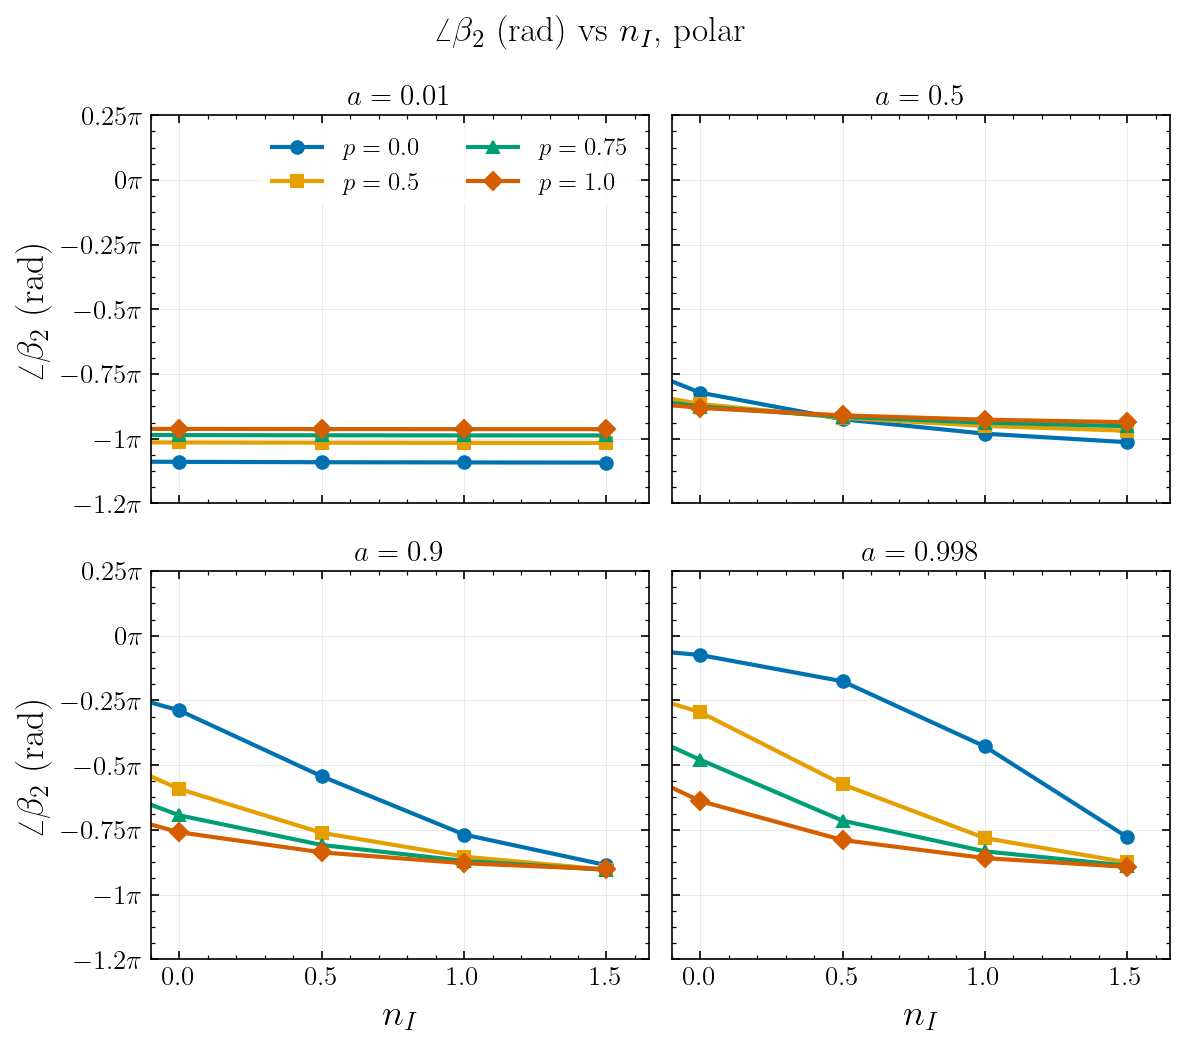

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_nI_by_spin_nopolar.png


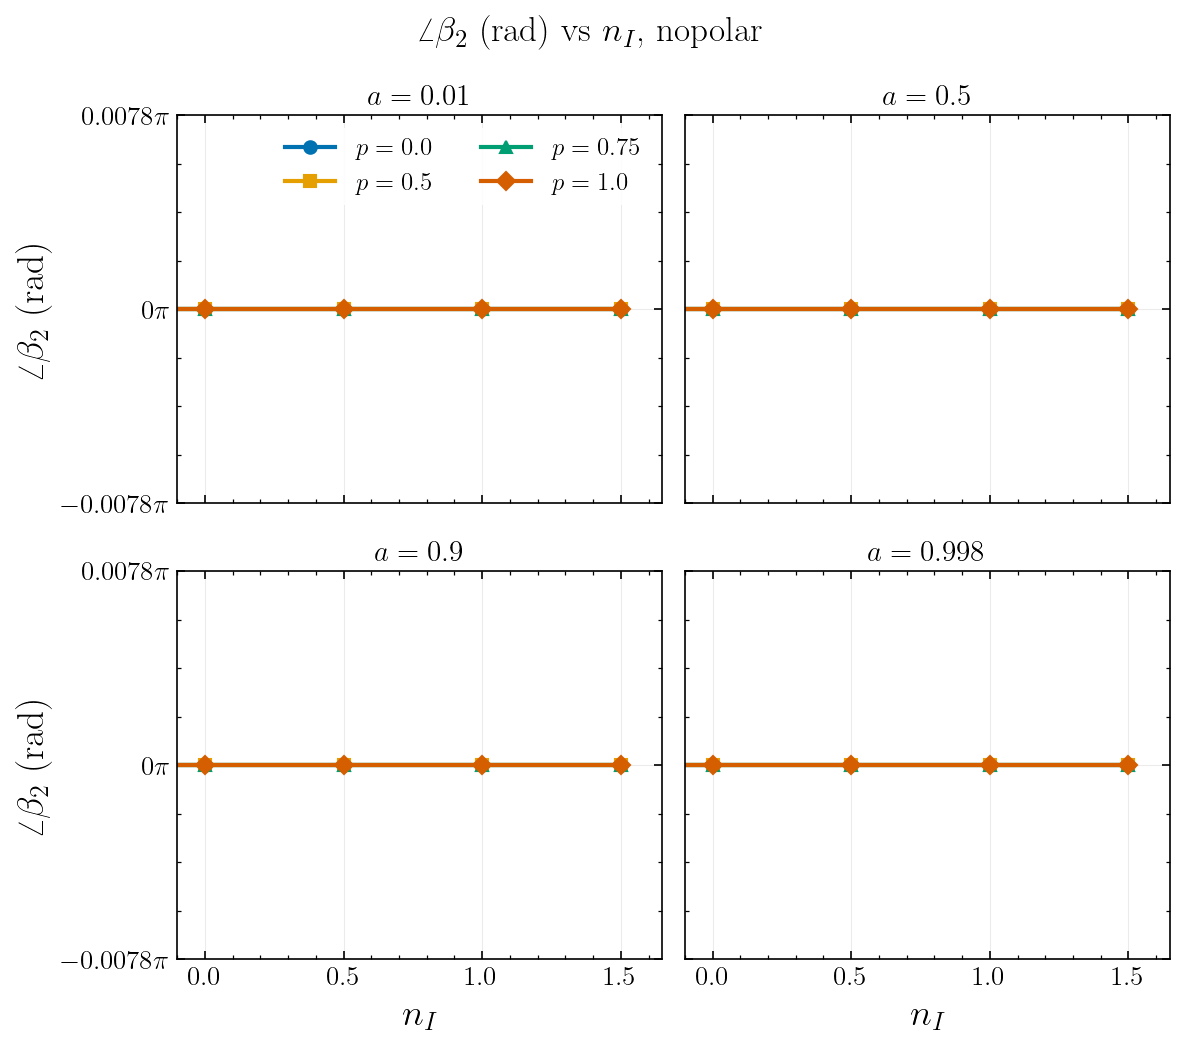

In [ ]:
def _branch(vals):
    v = np.asarray(vals, float).ravel()
    v = v[np.isfinite(v)]
    lo = (np.angle(np.mean(np.exp(1j * v))) - np.pi) if v.size else -np.pi
    return lo, lo + 2*np.pi, (lambda x: (np.asarray(x, float) - lo) % (2*np.pi) + lo)

_NICE = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128])

def _pi_lims(vals, pad=0.08, min_ticks=4):
    v = np.asarray(vals, float); v = v[np.isfinite(v)]
    if v.size == 0:
        return -np.pi, np.pi, 4
    span = max(v.max() - v.min(), 1e-3 * np.pi)
    lo_d, hi_d = v.min() - pad * span, v.max() + pad * span
    ok = _NICE[_NICE >= min_ticks * np.pi / (hi_d - lo_d)]
    sc = int(ok[0]) if ok.size else int(_NICE[-1])
    step = np.pi / sc
    return np.floor(lo_d / step) * step, np.ceil(hi_d / step) * step, sc

def _plot(ax, x, y, wrapped=False, **kw):
    x = np.asarray(x, float); y = np.asarray(y, float)
    if wrapped and x.size > 1:
        c = np.where(np.abs(np.diff(y)) > np.pi)[0] + 1
        if c.size:
            x, y = np.insert(x, c, np.nan), np.insert(y, c, np.nan)
    return ax.plot(x, y, **kw)


# observable vs n_I; separate figures for polarized and unpolarized
# 2x2 panels by spin, lines = p
for obs, meta in all_obs.items():
    for df, tag, fname in [(df_pol, 'polar',   'polar'),
                           (df_nop, 'nopolar', 'nopolar')]:

        if df is None or obs not in df.columns:
            continue
        if tag == 'unpolarized' and obs not in OBS_SHARED:
            continue

        fig, axes = plt.subplots(2, 2, figsize=(8.0, 7.0),
                                 sharex=True, sharey=True)
        axes = axes.flatten()

        if meta['pi']:
            pool = df[obs].values
            lo, hi, wrap = _branch(pool)
        else:
            pool = None
            lo = hi = None
            wrap = lambda z: np.asarray(z, float)

        for ax, spin in zip(axes, a_vals):
            for (p, color, marker) in zip(pvals, COLORS_P, MARKERS):
                d = df[(df['spin'] == spin) &
                       (df['p_val'] == p)].sort_values('n_I')
                if not d.empty:
                    _plot(ax, d['n_I'], wrap(d[obs]), wrapped=meta['pi'],
                          color=color, marker=marker, ms=6, lw=2.0, ls='-',
                          label=rf'$p={p}$')
            ax.set_title(rf'$a={spin}$', fontsize=14, pad=5)
            ax.set_xlim(-0.1, 1.65)
            ax.set_xticks([0.0, 0.5, 1.0, 1.5])
            ax.tick_params(labelsize=13)

        if meta['pi'] and lo is not None:
            ylo, yhi, sc = _pi_lims(wrap(pool))
            if meta.get('ylim') is not None:
                ylo, yhi = meta['ylim']
                sc = meta.get('pi_scale', 4)
            for ax in axes:
                pi_formatter(ax, scale=sc)
            axes[0].set_ylim(ylo, yhi)

        for ax in axes[2:]:
            ax.set_xlabel(r'$n_I$', fontsize=18)
        for ax in [axes[0], axes[2]]:
            ax.set_ylabel(meta['label'], fontsize=18)

        handles, labels = axes[0].get_legend_handles_labels()
        axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                       fontsize=12, ncol=2, loc='best')

        fig.suptitle(rf'{meta["label"]} vs $n_I$, {tag}',
                     fontsize=18, y=0.99)
        fig.tight_layout()
        save_fig(fig, f'{obs}_vs_nI_by_spin_{fname}.png')
        plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_p_by_spin_polar.png


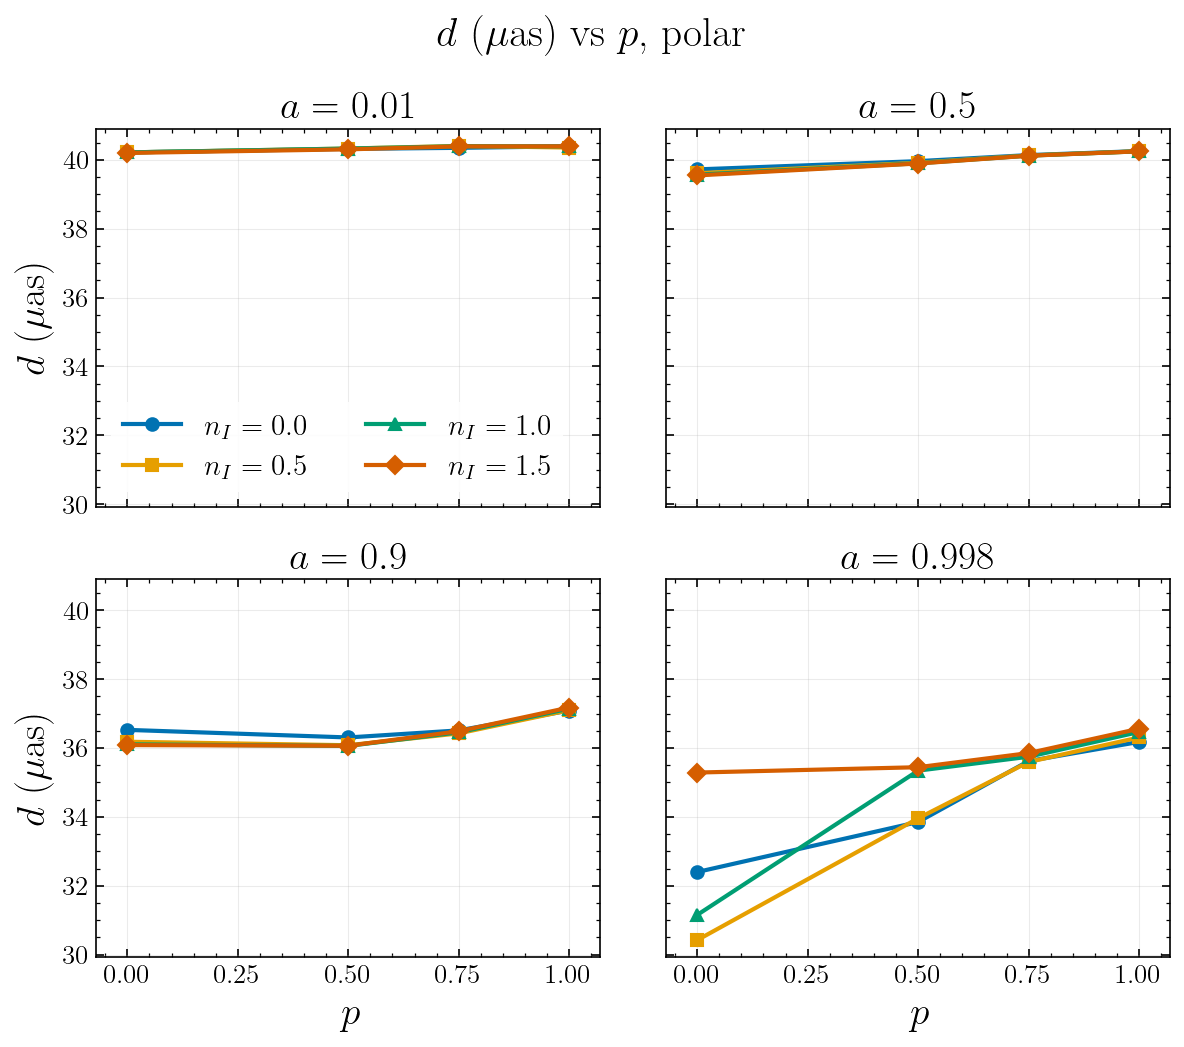

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_p_by_spin_nopolar.png


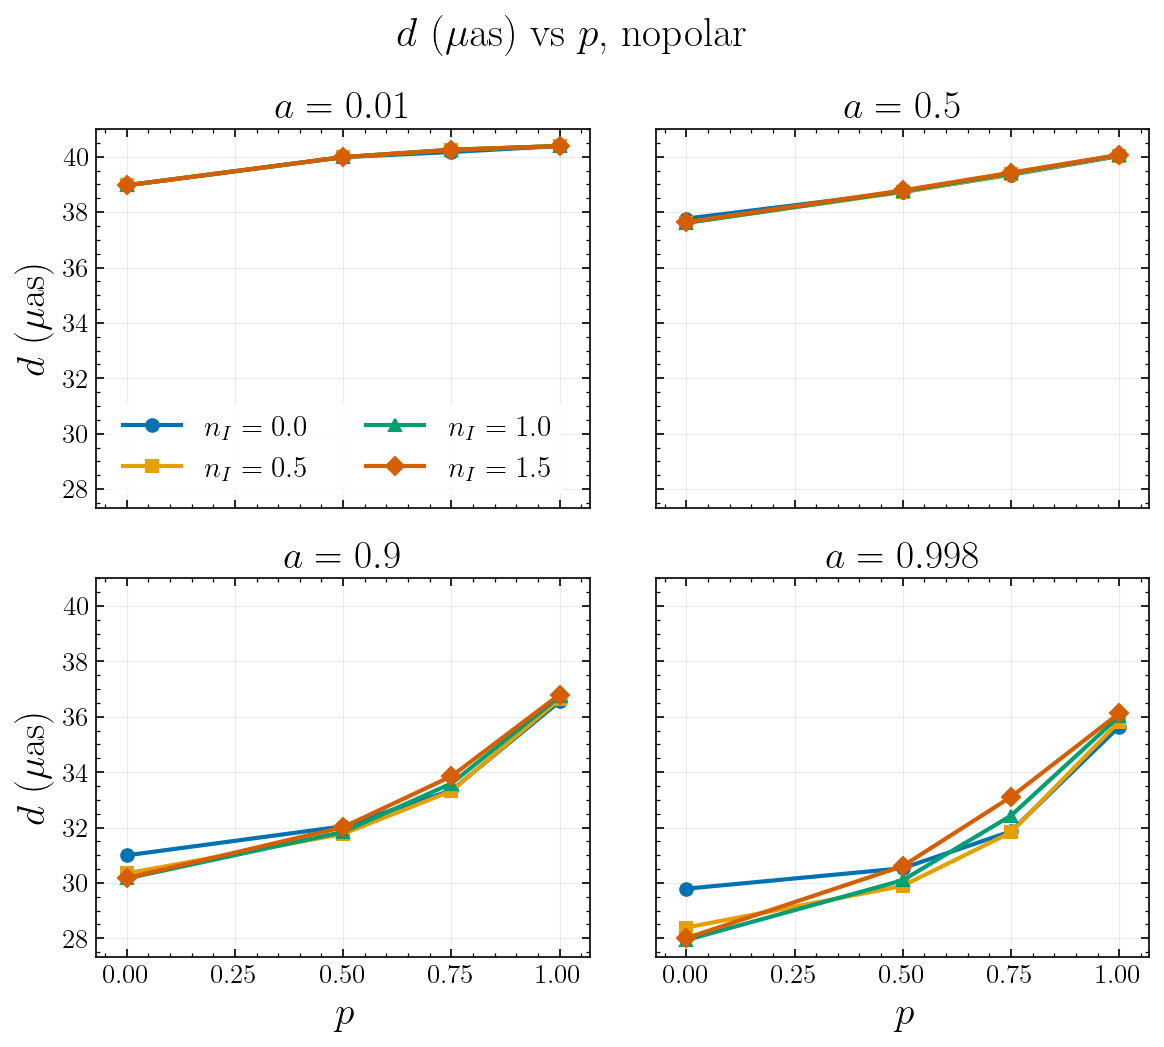

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_p_by_spin_polar.png


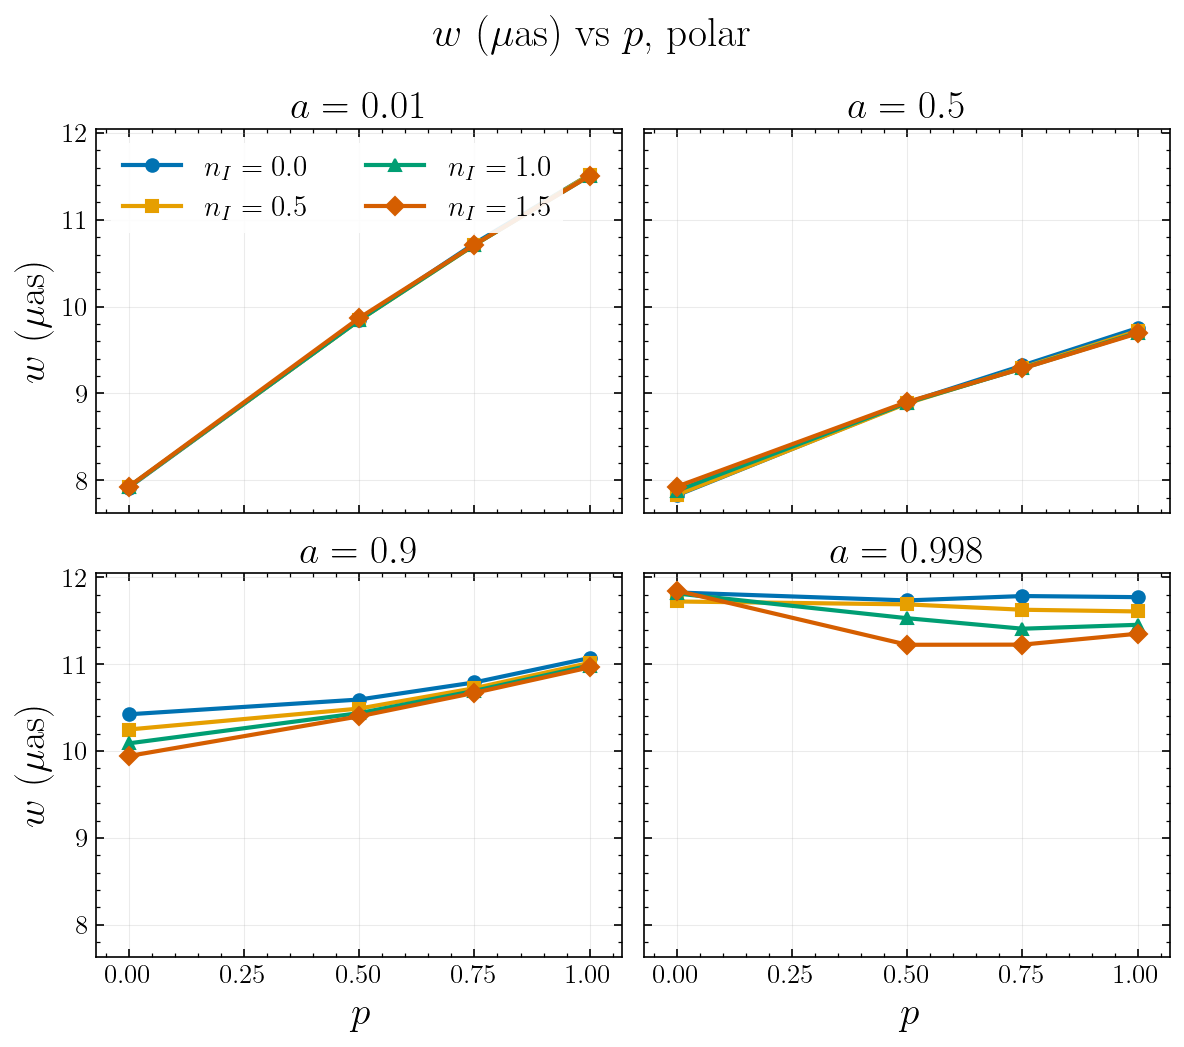

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_p_by_spin_nopolar.png


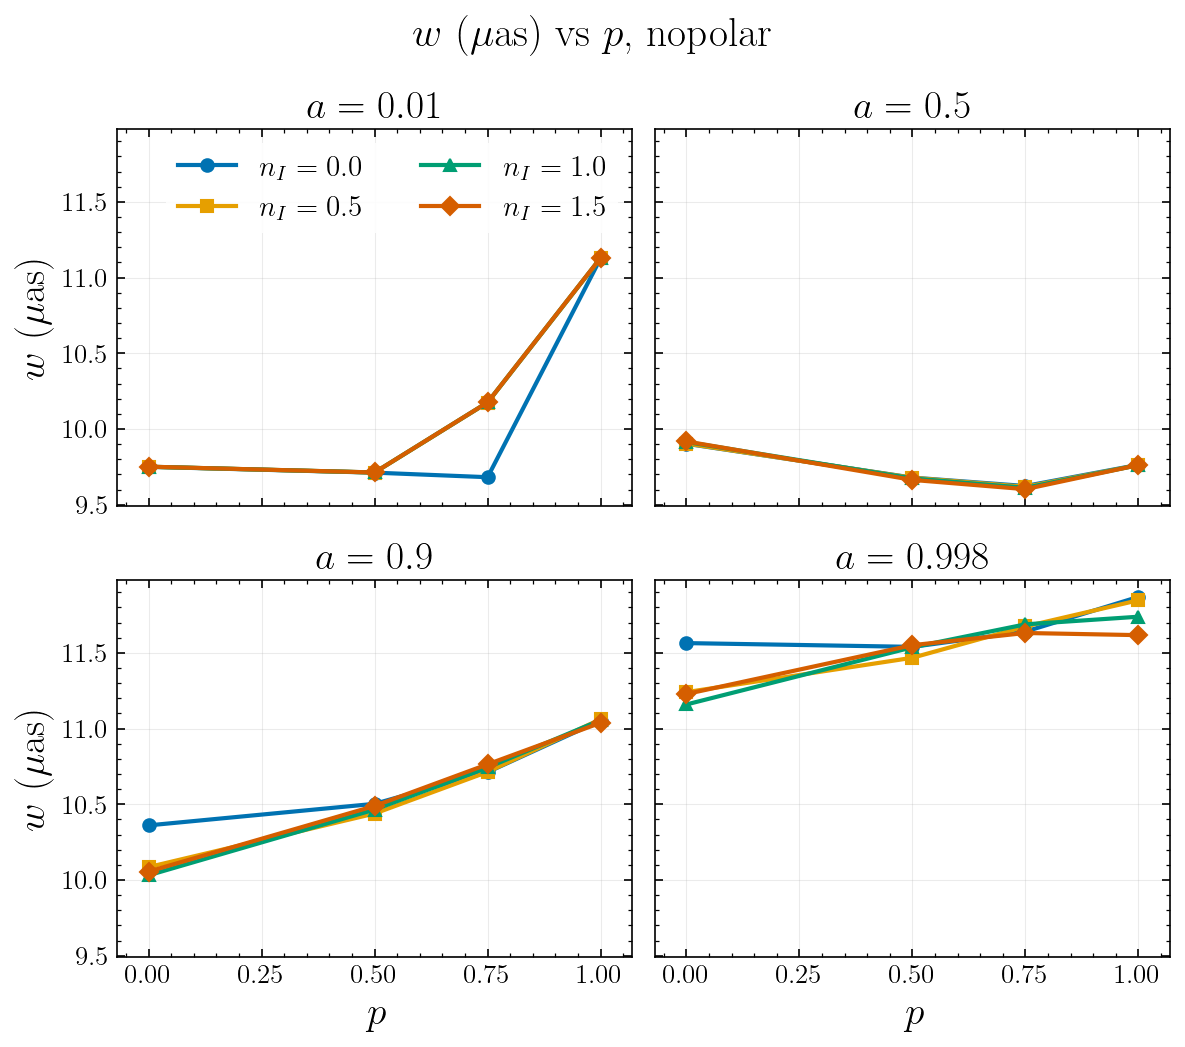

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_p_by_spin_polar.png


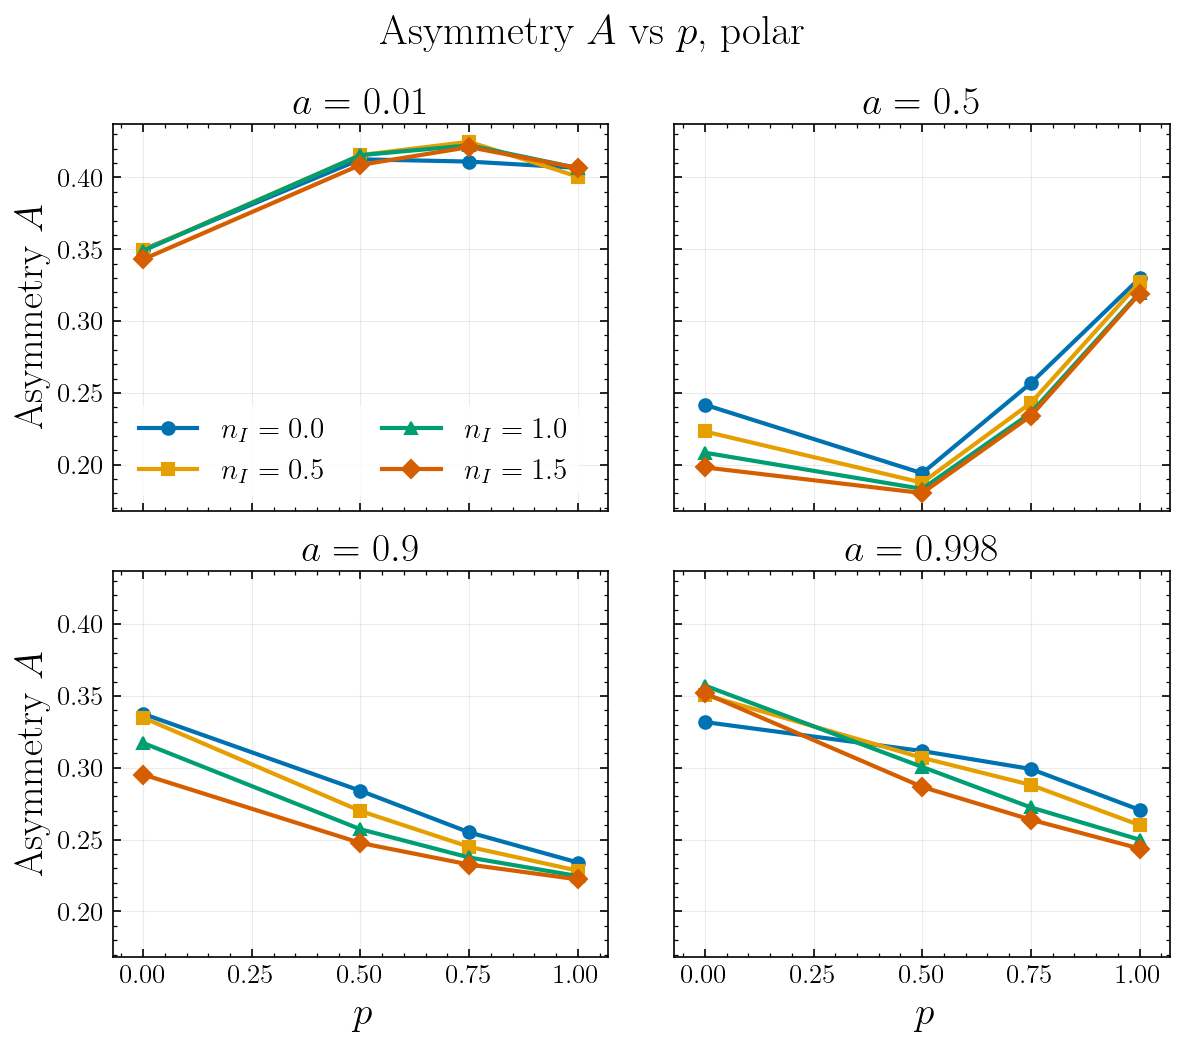

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_p_by_spin_nopolar.png


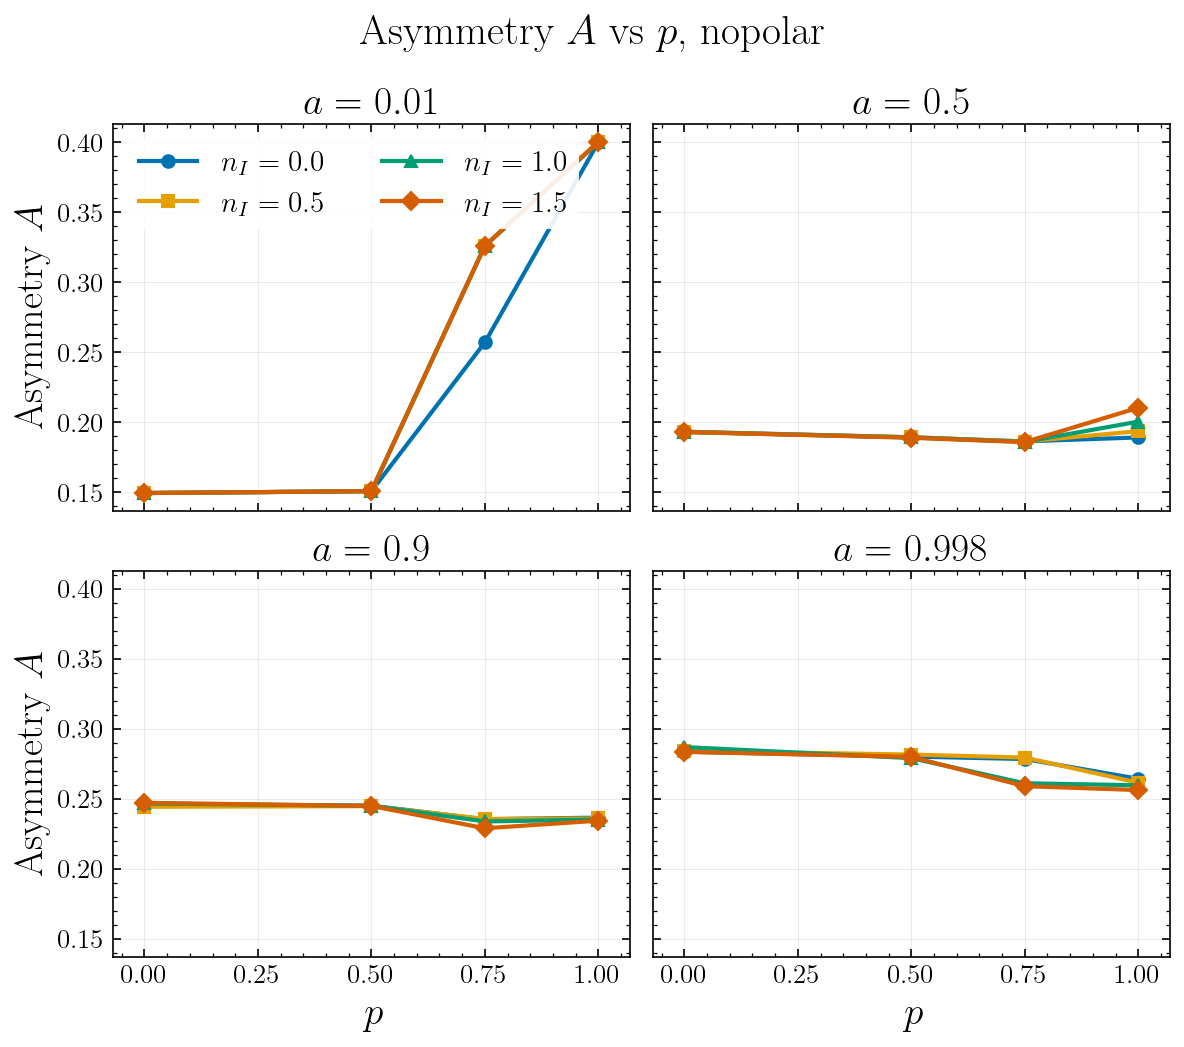

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_p_by_spin_polar.png


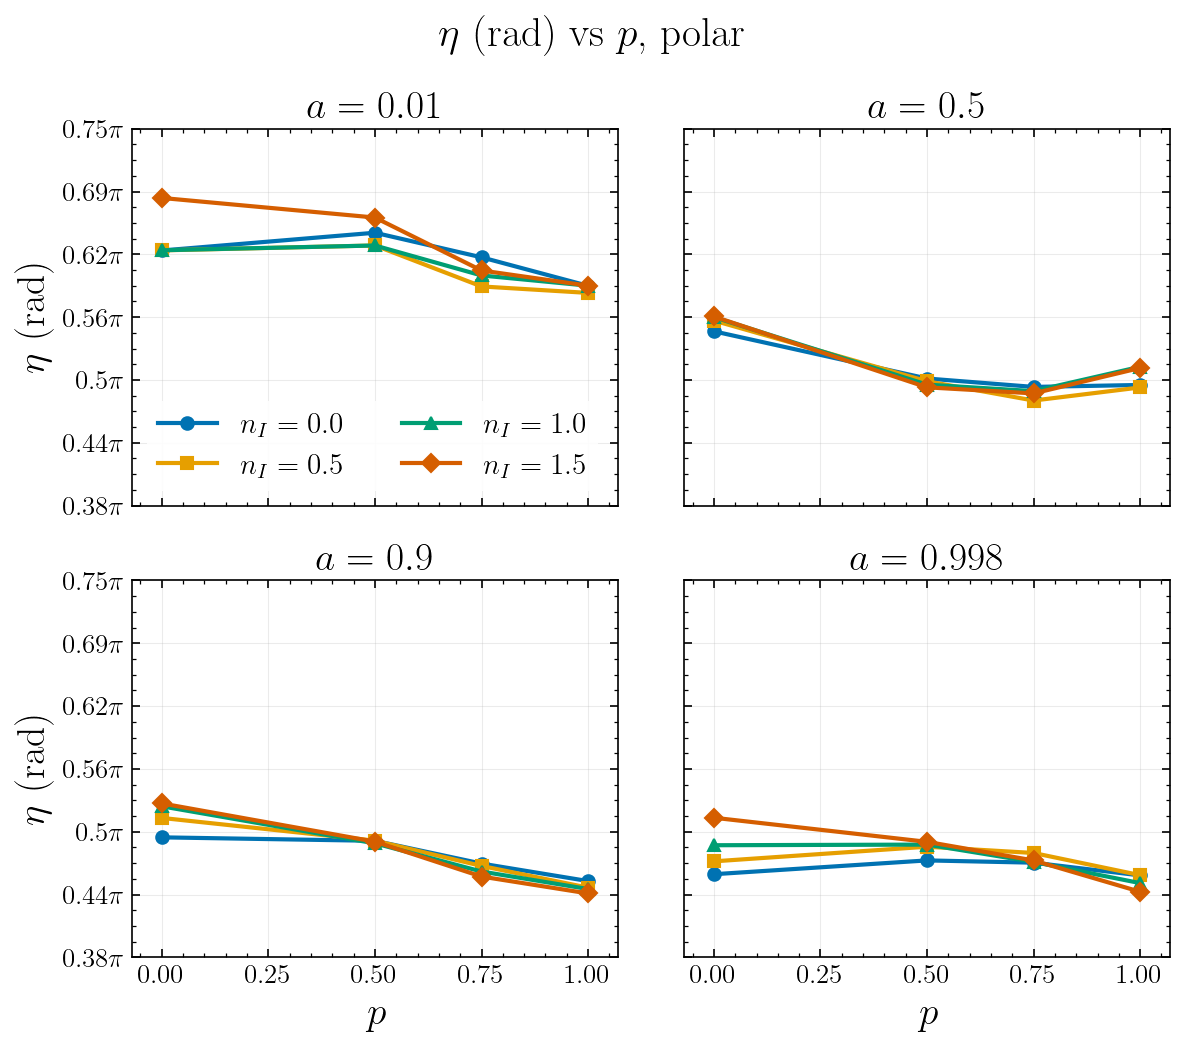

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_p_by_spin_nopolar.png


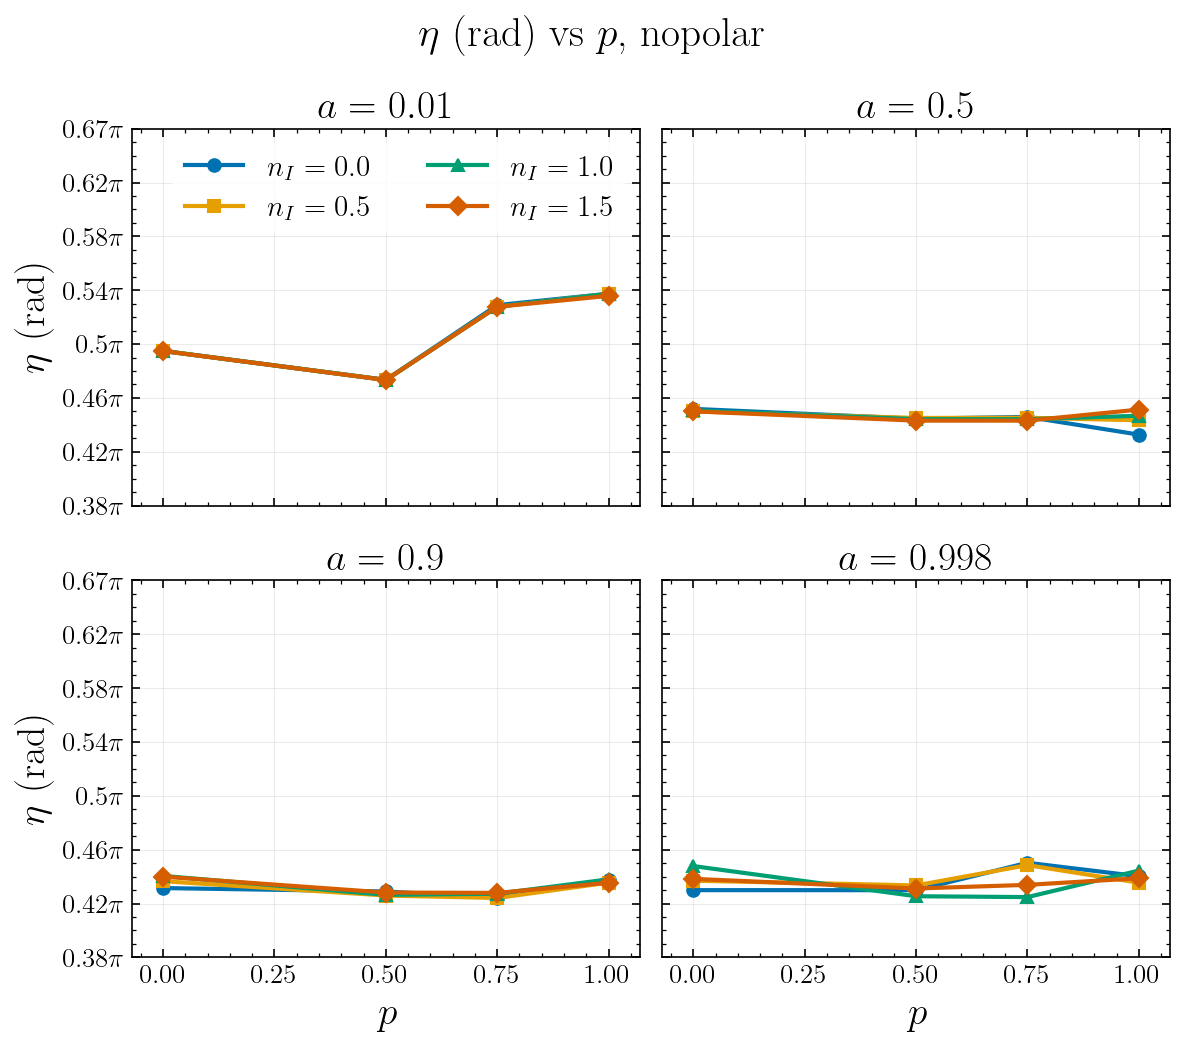

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_p_by_spin_polar.png


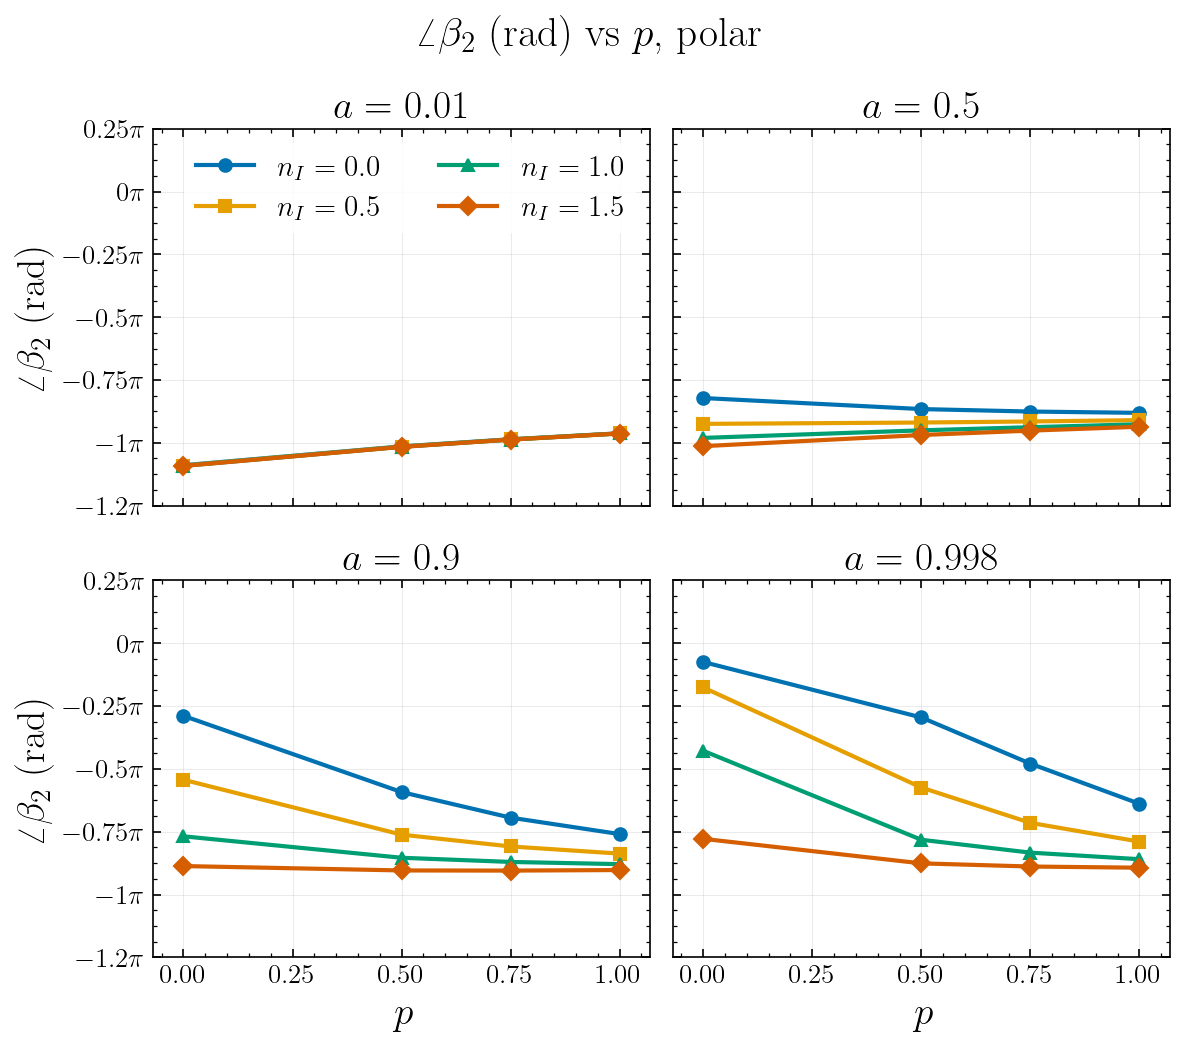

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_p_by_spin_nopolar.png


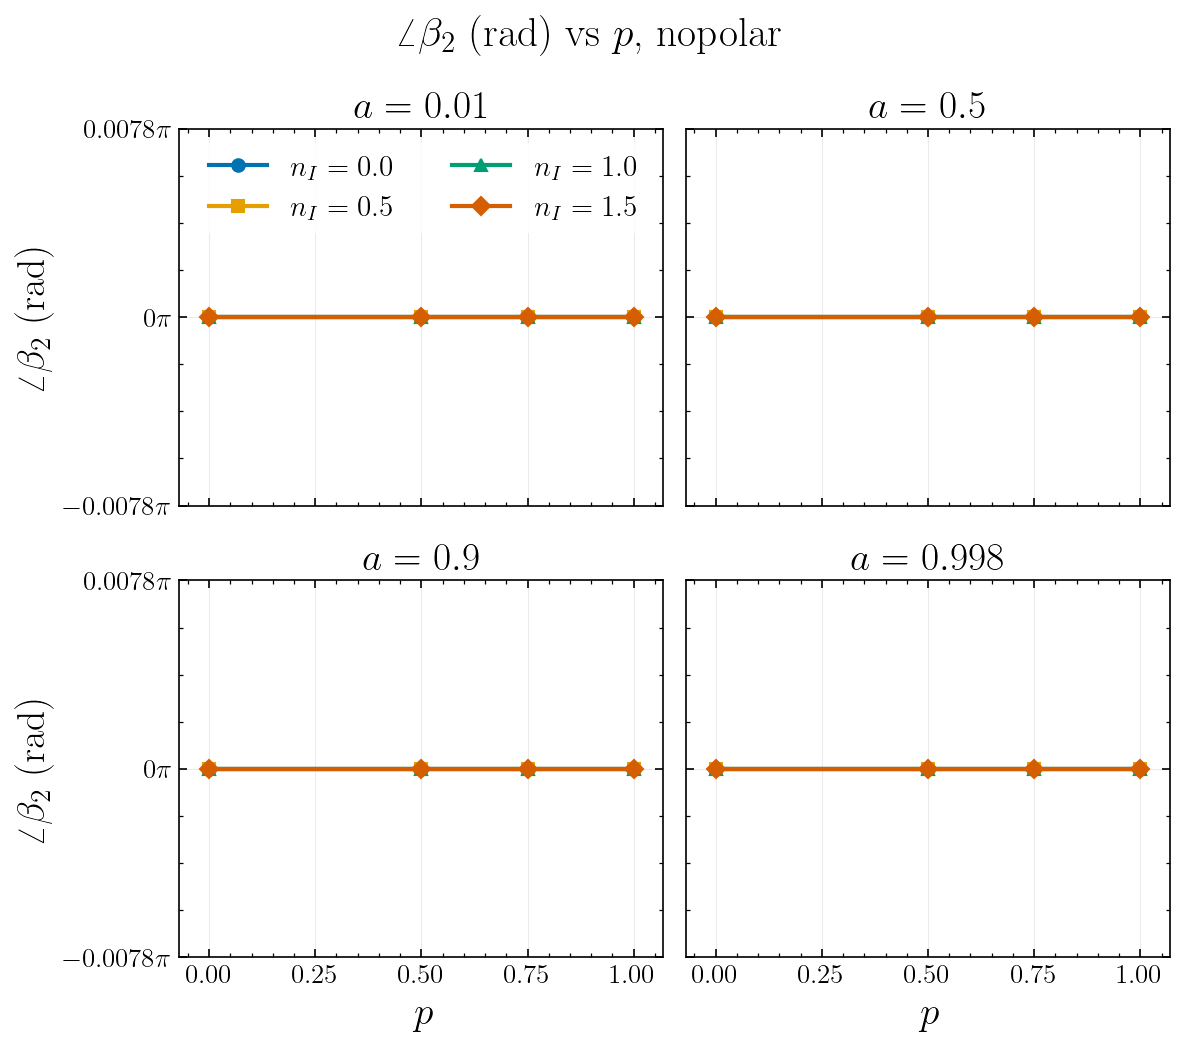

In [47]:
# observable vs p; separate figures for polarized and unpolarized
# 2x2 panels by spin, lines = n_I
for obs, meta in all_obs.items():
    for df, tag, fname in [(df_pol, 'polar',   'polar'),
                           (df_nop, 'nopolar', 'nopolar')]:

        if df is None or obs not in df.columns:
            continue
        if tag == 'unpolarized' and obs not in OBS_SHARED:
            continue

        fig, axes = plt.subplots(2, 2, figsize=(8.0, 7.0),
                                 sharex=True, sharey=True)
        axes = axes.flatten()

        if meta['pi']:
            pool = df[obs].values
            lo, hi, wrap = _branch(pool)
        else:
            pool = None
            lo = hi = None
            wrap = lambda z: np.asarray(z, float)

        for ax, spin in zip(axes, a_vals):
            for (n_I, color, marker) in zip(nvals, COLORS_N, MARKERS):
                d = df[(df['spin'] == spin) &
                       (df['n_I'] == n_I)].sort_values('p_val')
                if not d.empty:
                    _plot(ax, d['p_val'], wrap(d[obs]), wrapped=meta['pi'],
                          color=color, marker=marker, ms=6, lw=2.0, ls='-',
                          label=rf'$n_I={n_I}$')
            ax.set_title(rf'$a={spin}$', fontsize=19, pad=5)
            ax.set_xlim(-0.07, 1.07)
            ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
            ax.tick_params(labelsize=13)

        if meta['pi'] and lo is not None:
            ylo, yhi, sc = _pi_lims(wrap(pool))
            if meta.get('ylim') is not None:
                ylo, yhi = meta['ylim']
                sc = meta.get('pi_scale', 4)
            for ax in axes:
                pi_formatter(ax, scale=sc)
            axes[0].set_ylim(ylo, yhi)

        for ax in axes[2:]:
            ax.set_xlabel(r'$p$', fontsize=19)
        for ax in [axes[0], axes[2]]:
            ax.set_ylabel(meta['label'], fontsize=19)

        handles, labels = axes[0].get_legend_handles_labels()
        axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                       fontsize=14, ncol=2, loc='best')

        fig.suptitle(rf'{meta["label"]} vs $p$, {tag}',
                     fontsize=20, y=0.99)
        fig.tight_layout()
        save_fig(fig, f'{obs}_vs_p_by_spin_{fname}.png')
        plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_p_nI_single_a0.5.png


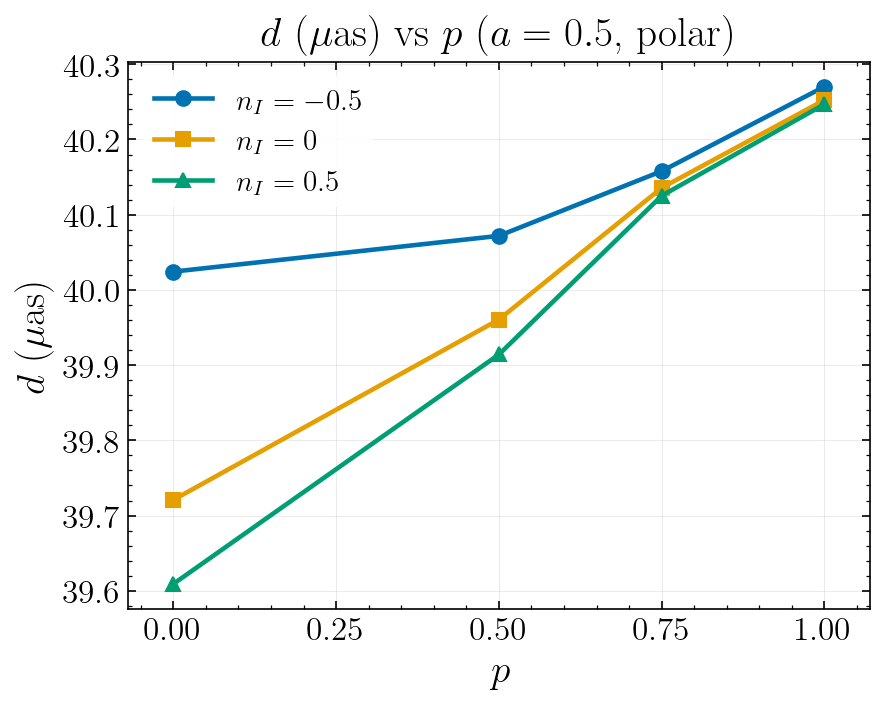

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_p_nI_single_a0.5.png


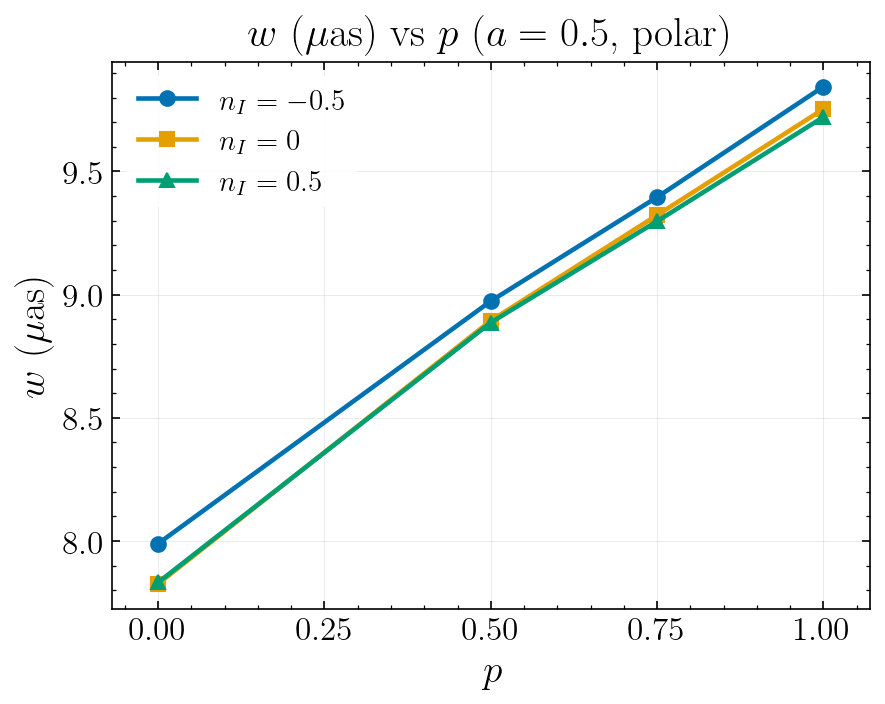

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_p_nI_single_a0.5.png


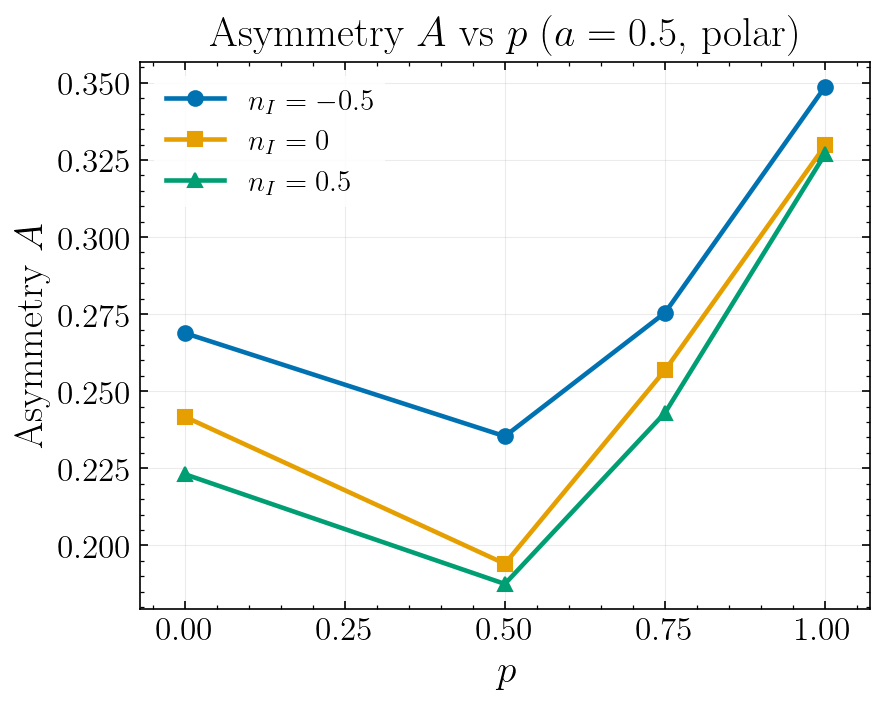

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_p_nI_single_a0.5.png


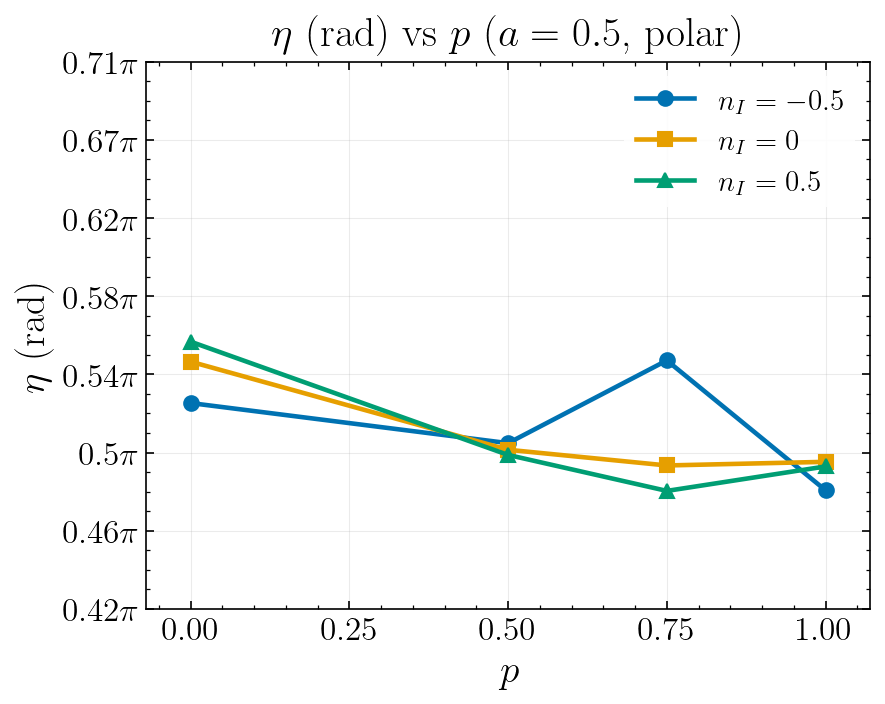

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_p_nI_single_a0.5.png


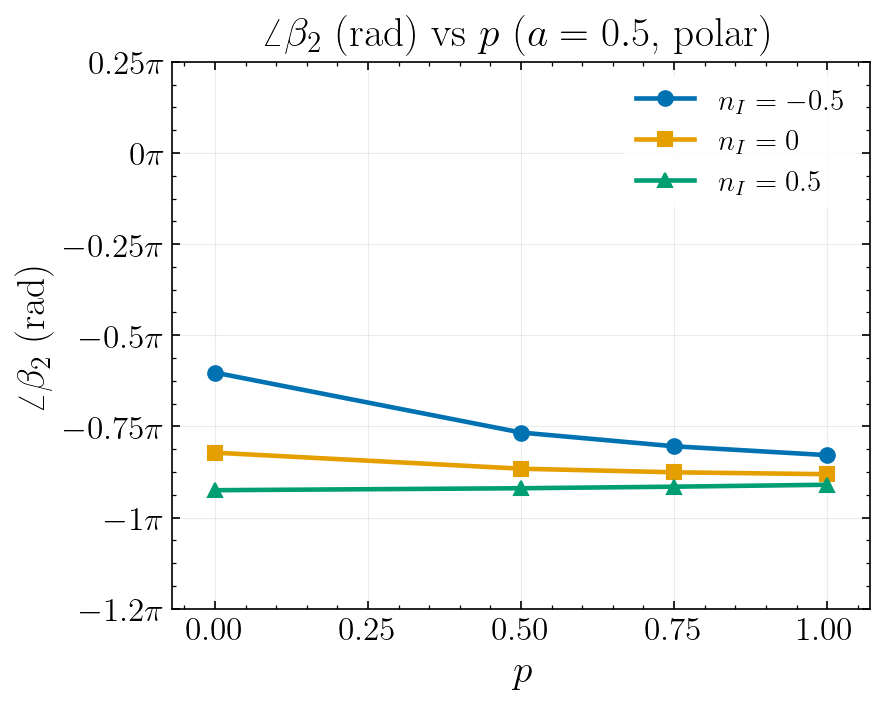

In [48]:
# single panel: observable vs p, lines = n_I, polarized only
SPIN_FIX = 0.5
NI_SHOW  = [-0.5, 0.0, 0.5]

for obs, meta in all_obs.items():
    if obs not in df_pol.columns:
        continue

    fig, ax = plt.subplots(figsize=(6.0, 4.8))

    if meta['pi']:
        pool = df_pol[df_pol['n_I'].isin(NI_SHOW)][obs].values
        lo, hi, wrap = _branch(pool)
    else:
        pool = None
        lo = hi = None
        wrap = lambda z: np.asarray(z, float)

    for (n_I, color, marker) in zip(NI_SHOW, COLORS_N, MARKERS):
        d = df_pol[(df_pol['spin'] == SPIN_FIX) &
                   (np.isclose(df_pol['n_I'], n_I))].sort_values('p_val')
        if not d.empty:
            _plot(ax, d['p_val'], wrap(d[obs]), wrapped=meta['pi'],
                  color=color, marker=marker, ms=7, lw=2.2, ls='-',
                  label=rf'$n_I={n_I:g}$')

    ax.set_xlim(-0.07, 1.07)
    ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
    ax.tick_params(labelsize=16)
    ax.set_xlabel(r'$p$', fontsize=19)
    ax.set_ylabel(meta['label'], fontsize=19)

    if meta['pi'] and lo is not None:
        ylo, yhi, sc = _pi_lims(wrap(pool))
        if meta.get('ylim') is not None:
            ylo, yhi = meta['ylim']
            sc = meta.get('pi_scale', 4)
        pi_formatter(ax, scale=sc)
        ax.set_ylim(ylo, yhi)

    ax.legend(framealpha=0.9, edgecolor='none', fontsize=14, loc='best')
    ax.set_title(rf'{meta["label"]} vs $p$ ($a=0.5$, polar)', fontsize=20, pad=8)

    fig.tight_layout()
    save_fig(fig, f'{obs}_vs_p_nI_single_a{SPIN_FIX}.png')
    plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_nI_by_spin.png


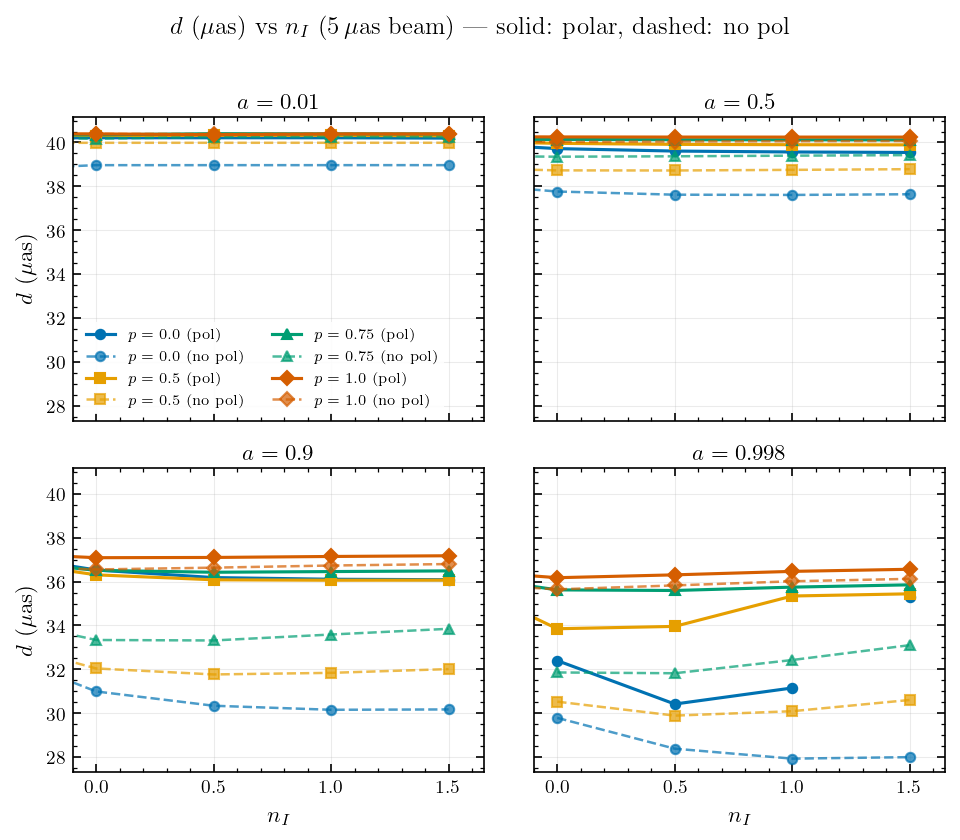

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_nI_by_spin.png


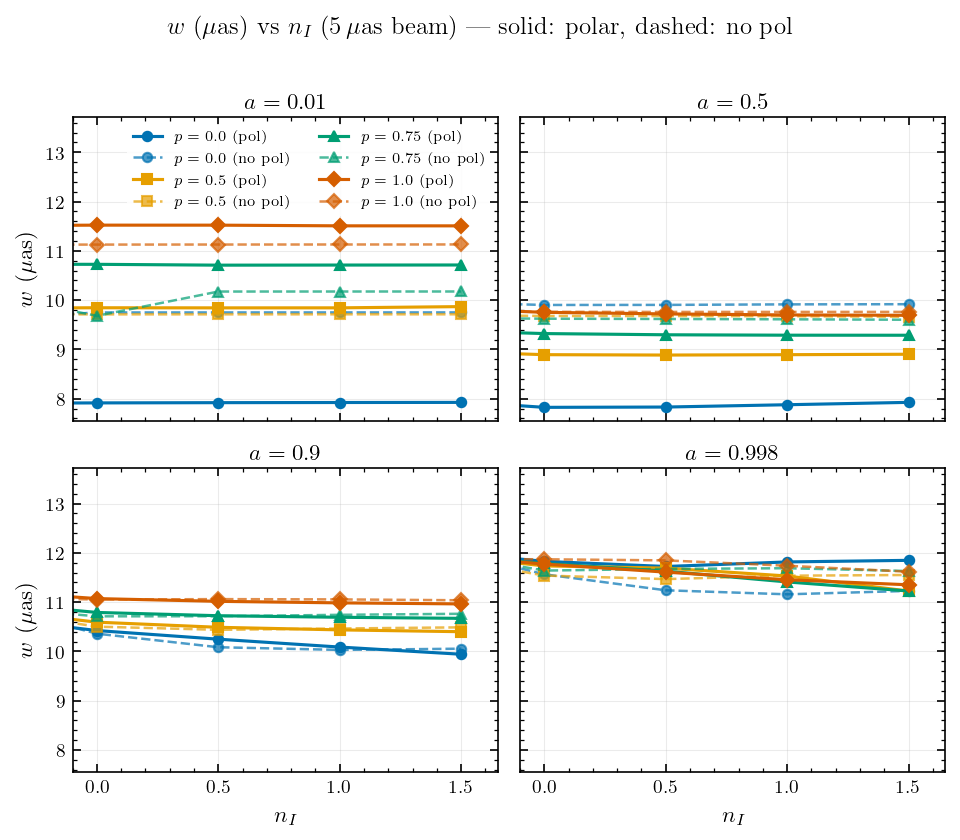

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_nI_by_spin.png


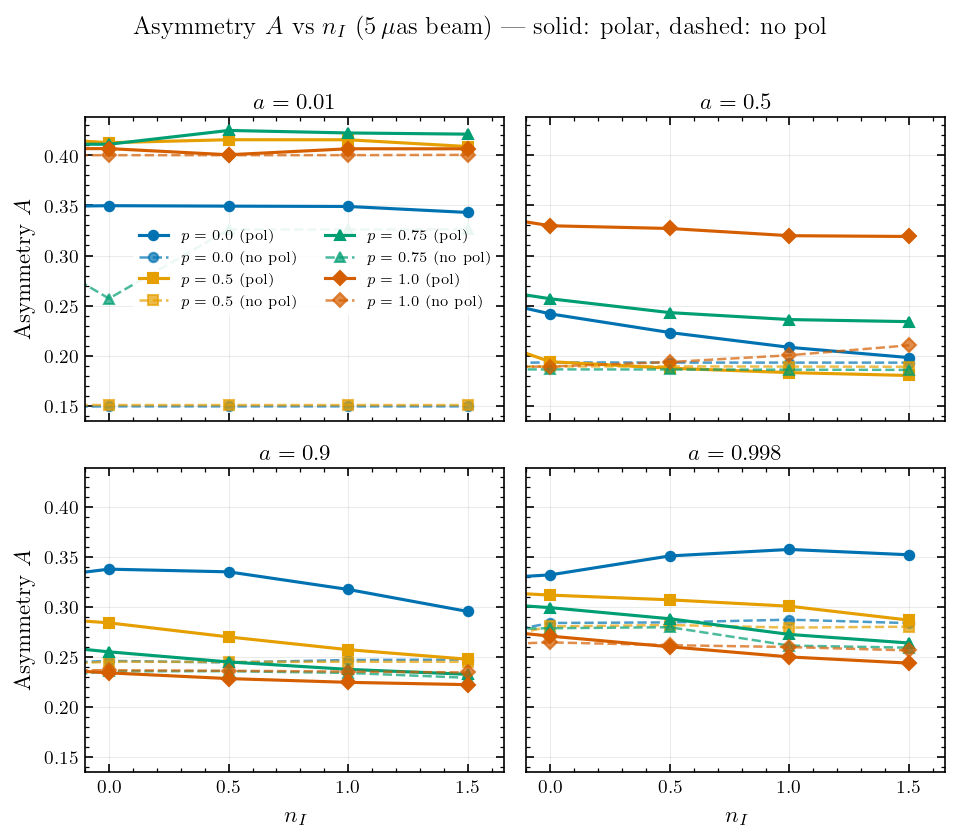

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_nI_by_spin.png


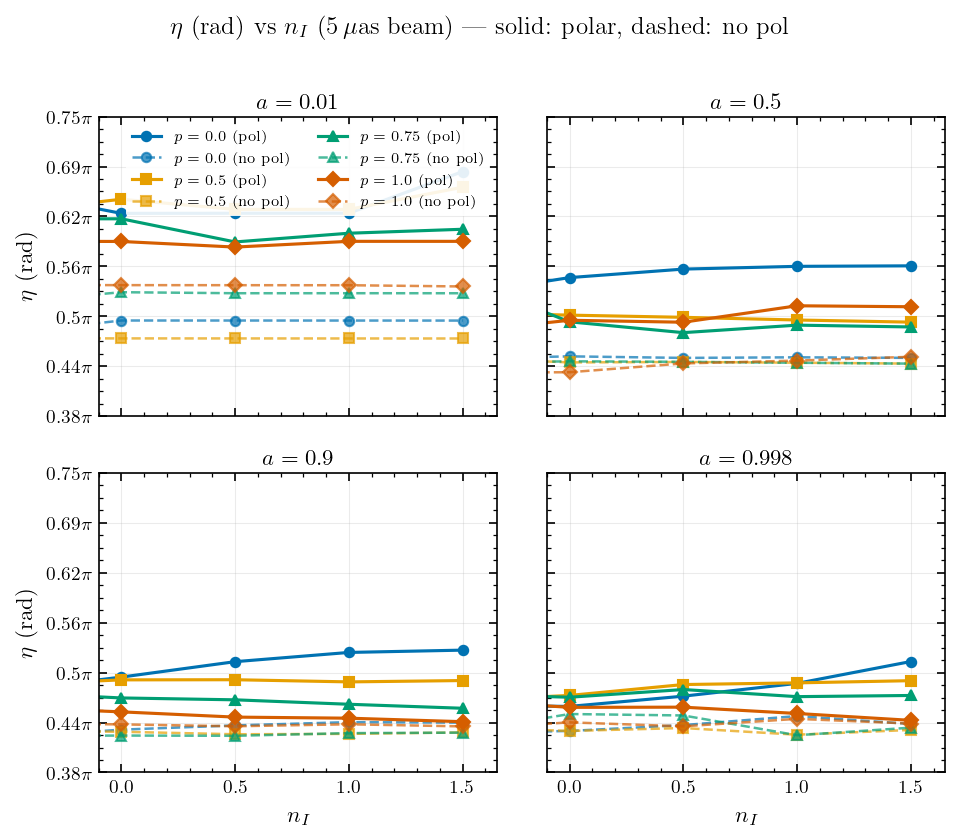

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_nI_by_spin.png


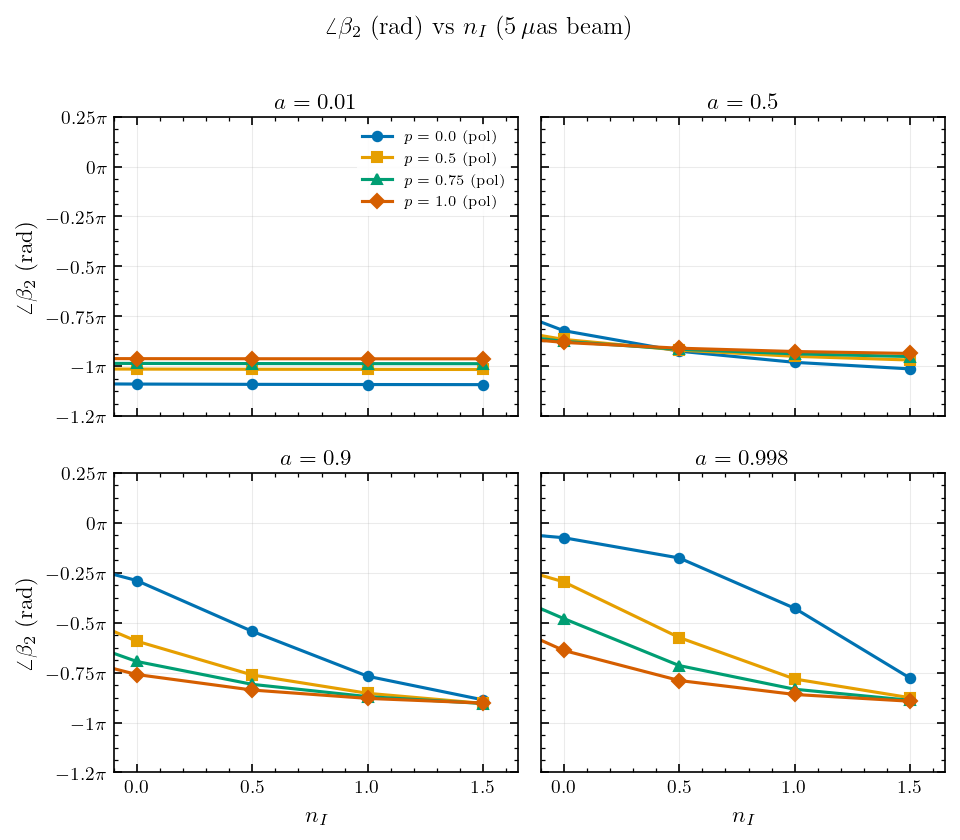

In [ ]:
def _branch(vals):
    v = np.asarray(vals, float).ravel()
    v = v[np.isfinite(v)]
    lo = (np.angle(np.mean(np.exp(1j * v))) - np.pi) if v.size else -np.pi
    return lo, lo + 2*np.pi, (lambda x: (np.asarray(x, float) - lo) % (2*np.pi) + lo)

_NICE = np.array([1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128])

def _pi_lims(vals, pad=0.08, min_ticks=4):
    v = np.asarray(vals, float); v = v[np.isfinite(v)]
    if v.size == 0:
        return -np.pi, np.pi, 4
    span = max(v.max() - v.min(), 1e-3 * np.pi)
    lo_d, hi_d = v.min() - pad * span, v.max() + pad * span
    ok = _NICE[_NICE >= min_ticks * np.pi / (hi_d - lo_d)]
    sc = int(ok[0]) if ok.size else int(_NICE[-1])
    step = np.pi / sc
    return np.floor(lo_d / step) * step, np.ceil(hi_d / step) * step, sc

def _plot(ax, x, y, **kw):
    x = np.asarray(x, float); y = np.asarray(y, float)
    c = np.where(np.abs(np.diff(y)) > np.pi)[0] + 1
    if c.size:
        x, y = np.insert(x, c, np.nan), np.insert(y, c, np.nan)
    return ax.plot(x, y, **kw)


# observable vs n_I 
# polar solid, non-polar dashed; 2x2 panels by spin; lines = p
for obs, meta in all_obs.items():
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.5),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    if meta['pi']:
        pool = []
        if obs in df_pol.columns:
            pool.append(df_pol[obs].values)
        if obs in OBS_SHARED and obs in df_nop.columns:
            pool.append(df_nop[obs].values)
        lo, hi, wrap = _branch(np.concatenate(pool)) if pool else (None, None, lambda z: z)
    else:
        lo = hi = None
        wrap = lambda z: np.asarray(z, float)

    for ax, spin in zip(axes, a_vals):
        for (p, color, marker) in zip(pvals, COLORS_P, MARKERS):
            d = df_pol[(df_pol['spin'] == spin) &
                       (df_pol['p_val'] == p)].sort_values('n_I')
            if not d.empty and obs in d.columns:
                _plot(ax, d['n_I'], wrap(d[obs]),
                      color=color, marker=marker, lw=1.5, ls='-',
                      label=rf'$p={p}$ (pol)')
            if obs in OBS_SHARED and obs in df_nop.columns:
                d2 = df_nop[(df_nop['spin'] == spin) &
                            (df_nop['p_val'] == p)].sort_values('n_I')
                if not d2.empty:
                    _plot(ax, d2['n_I'], wrap(d2[obs]),
                          color=color, marker=marker, lw=1.2, ls='--',
                          alpha=0.7,
                          label=rf'$p={p}$ (no pol)')
        ax.set_title(rf'$a={spin}$', pad=4)
        ax.set_xlim(-0.1, 1.65)
        ax.set_xticks([0.0, 0.5, 1.0, 1.5])

    # limits from the data span, not the full 2pi branch; ylim set AFTER the
    # formatter because set_yticks expands limits to contain its ticks
    if meta['pi'] and lo is not None:
        ylo, yhi, sc = _pi_lims(wrap(np.concatenate(pool)))
        if meta.get('ylim') is not None:
            ylo, yhi = meta['ylim']
            sc = meta.get('pi_scale', 4)
        for ax in axes:
            pi_formatter(ax, scale=sc)
        axes[0].set_ylim(ylo, yhi)

    for ax in axes[2:]:
        ax.set_xlabel(r'$n_I$')
    for ax in [axes[0], axes[2]]:
        ax.set_ylabel(meta['label'])

    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                   fontsize=7, ncol=2 if obs in OBS_SHARED else 1)

    
    fig.suptitle(
        rf'{meta["label"]} vs $n_I$  (5\,$\mu$as beam){suffix}',
        y=1.01
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_vs_nI_by_spin.png')
    plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_p_by_spin.png


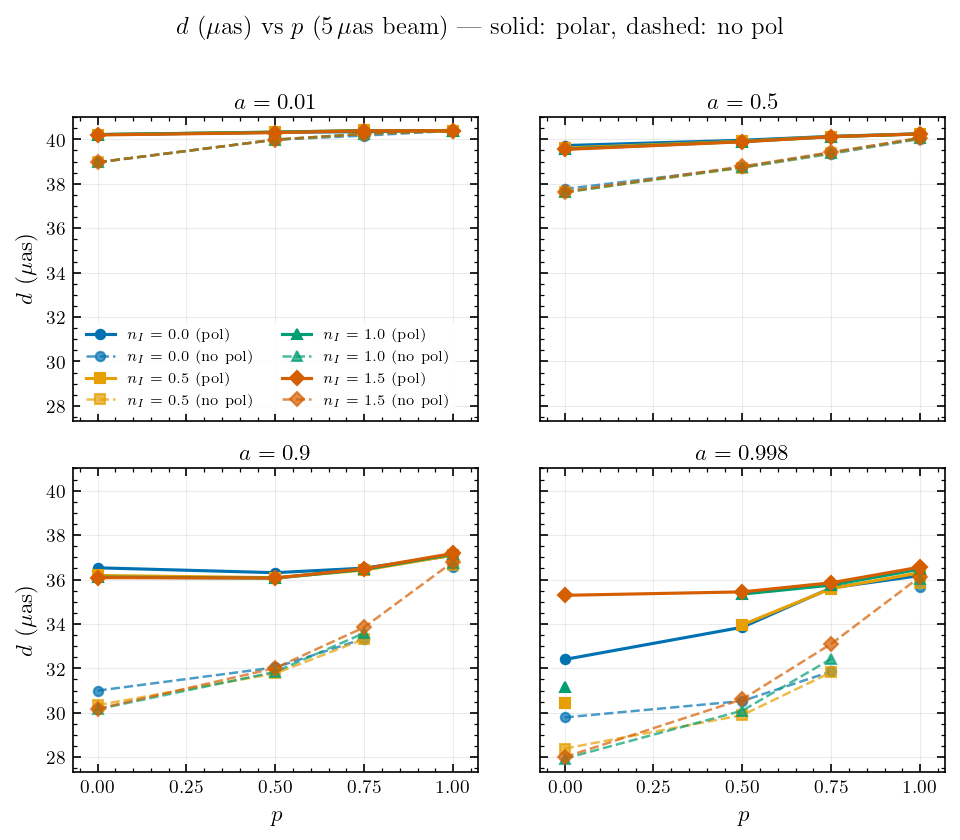

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_p_by_spin.png


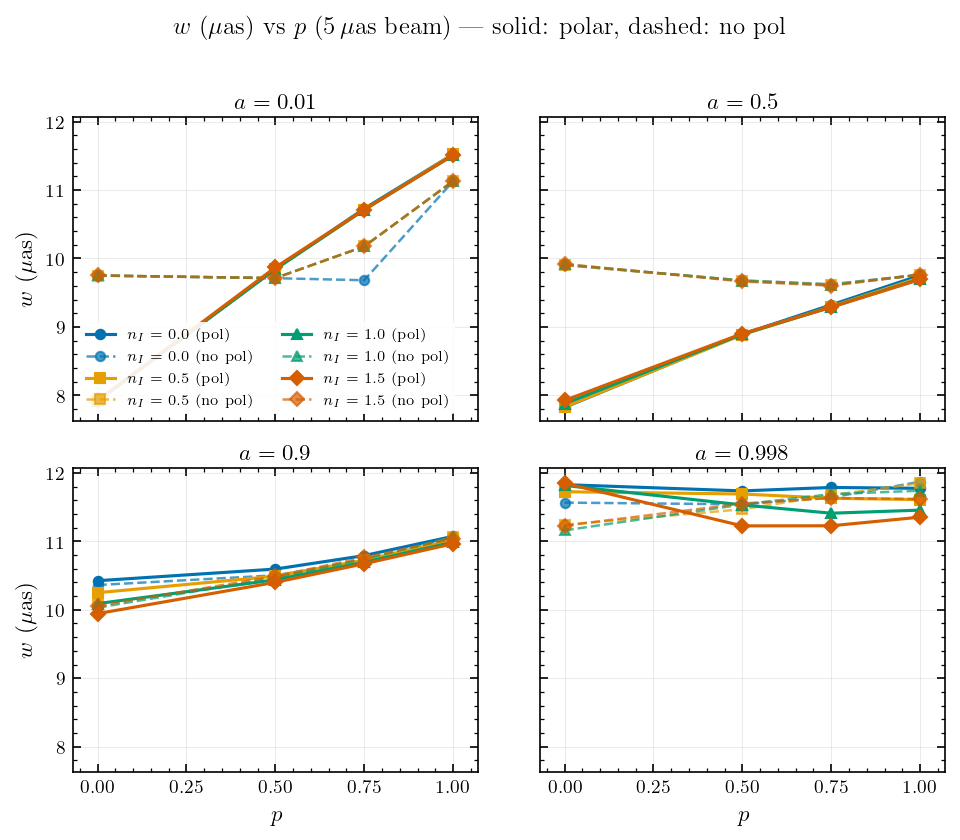

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_p_by_spin.png


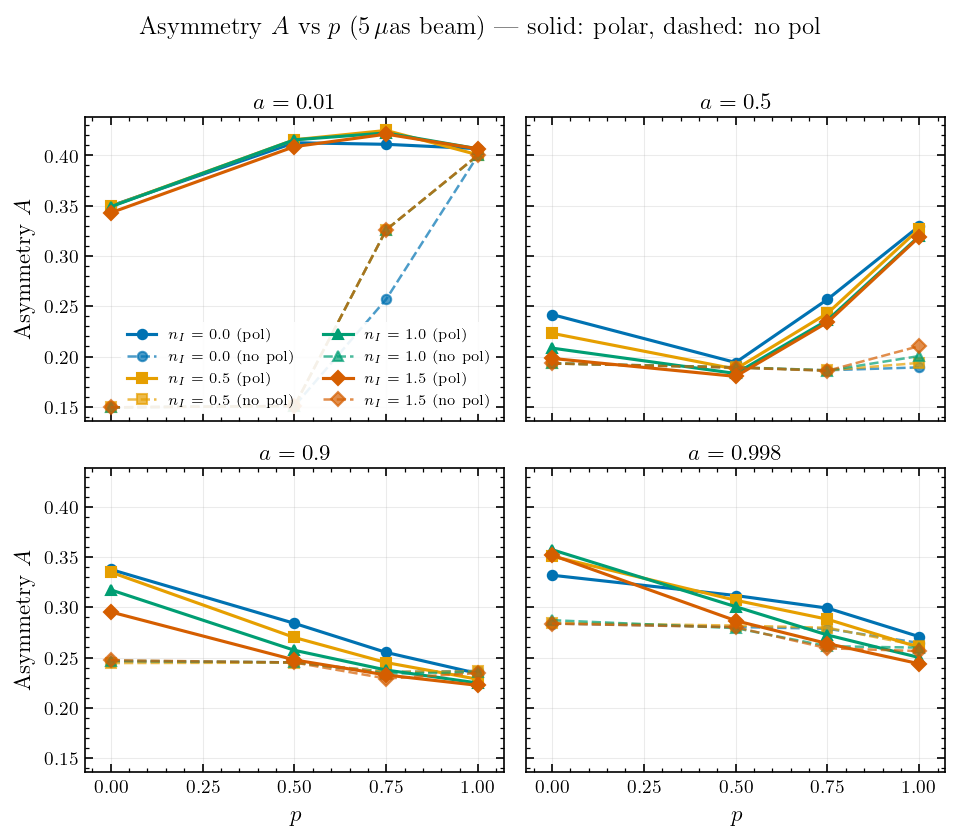

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_p_by_spin.png


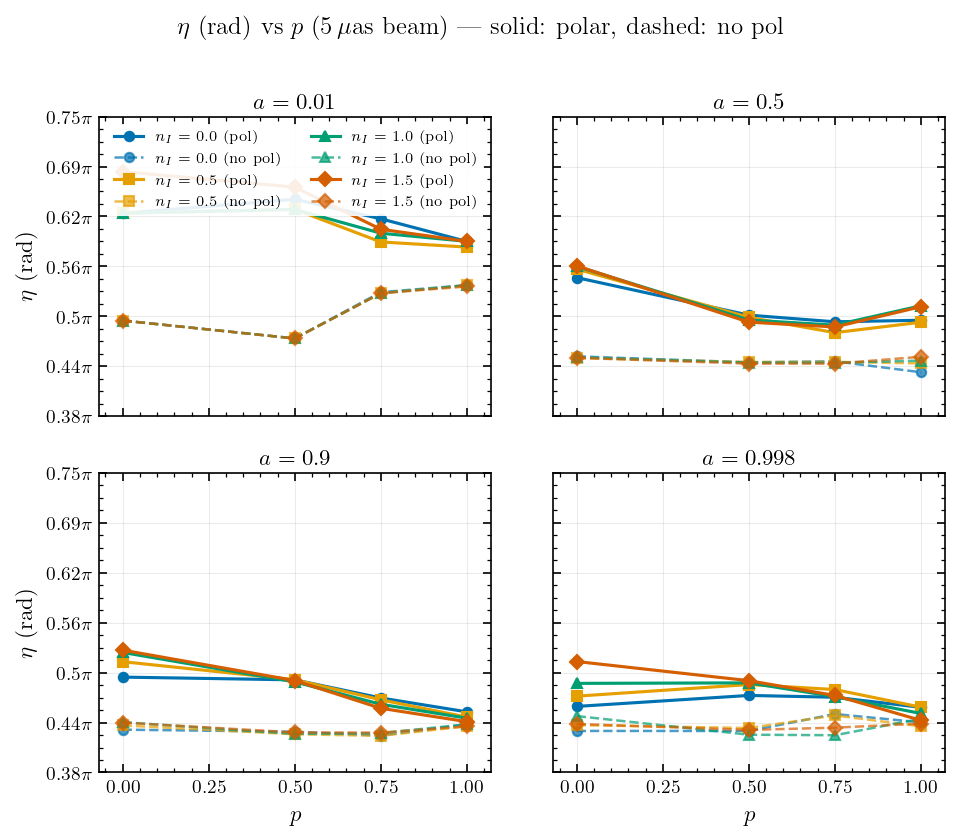

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_p_by_spin.png


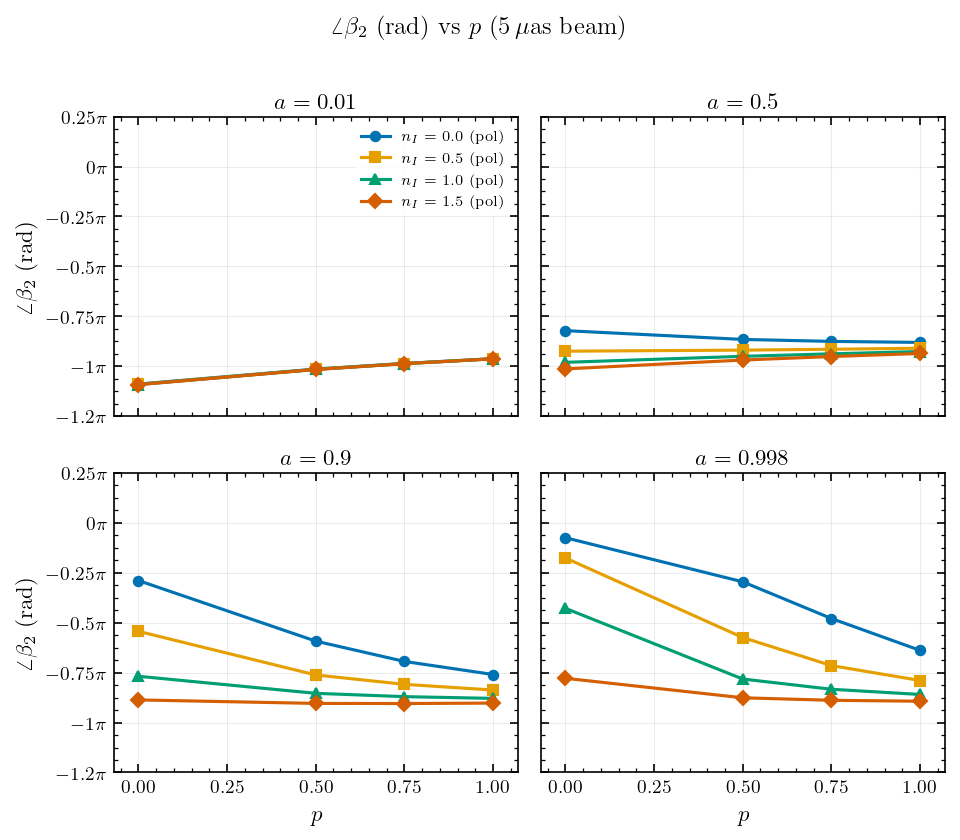

In [29]:
# observable vs p 
# polar solid, non-polar dashed; 2x2 panels by spin; lines = n_I
# assumes _branch, _pi_lims, _plot are already defined
for obs, meta in all_obs.items():
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.5),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    # one branch for the whole figure, from all data it will show
    if meta['pi']:
        pool = []
        if obs in df_pol.columns:
            pool.append(df_pol[obs].values)
        if obs in OBS_SHARED and obs in df_nop.columns:
            pool.append(df_nop[obs].values)
        lo, hi, wrap = _branch(np.concatenate(pool)) if pool else (None, None, lambda z: z)
    else:
        lo = hi = None
        wrap = lambda z: np.asarray(z, float)

    for ax, spin in zip(axes, a_vals):
        for (n_I, color, marker) in zip(nvals, COLORS_N, MARKERS):
            d = df_pol[(df_pol['spin'] == spin) &
                       (df_pol['n_I'] == n_I)].sort_values('p_val')
            if not d.empty and obs in d.columns:
                _plot(ax, d['p_val'], wrap(d[obs]),
                      color=color, marker=marker, lw=1.5, ls='-',
                      label=rf'$n_I={n_I}$ (pol)')
            if obs in OBS_SHARED and obs in df_nop.columns:
                d2 = df_nop[(df_nop['spin'] == spin) &
                            (df_nop['n_I'] == n_I)].sort_values('p_val')
                if not d2.empty:
                    _plot(ax, d2['p_val'], wrap(d2[obs]),
                          color=color, marker=marker, lw=1.2, ls='--',
                          alpha=0.7,
                          label=rf'$n_I={n_I}$ (no pol)')
        ax.set_title(rf'$a={spin}$', pad=4)
        ax.set_xlim(-0.07, 1.07)
        ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])


    if meta['pi'] and lo is not None:
        ylo, yhi, sc = _pi_lims(wrap(np.concatenate(pool)))
        if meta.get('ylim') is not None:
            ylo, yhi = meta['ylim']
            sc = meta.get('pi_scale', 4)
        for ax in axes:
            pi_formatter(ax, scale=sc)
        axes[0].set_ylim(ylo, yhi)

    for ax in axes[2:]:
        ax.set_xlabel(r'$p$')
    for ax in [axes[0], axes[2]]:
        ax.set_ylabel(meta['label'])

    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                   fontsize=7, ncol=2 if obs in OBS_SHARED else 1)

    suffix = ' — solid: polar, dashed: no pol' if obs in OBS_SHARED else ''
    fig.suptitle(
        rf'{meta["label"]} vs $p$  (5\,$\mu$as beam){suffix}',
        y=1.01
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_vs_p_by_spin.png')
    plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_vs_spin_by_nI.png


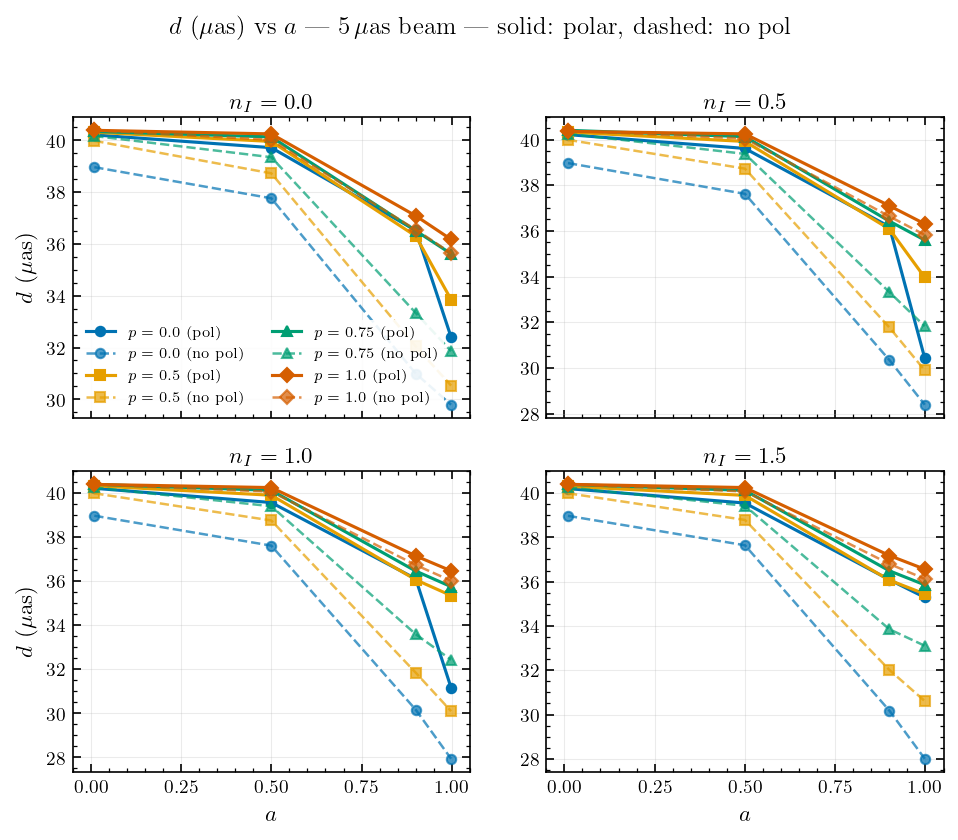

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_vs_spin_by_nI.png


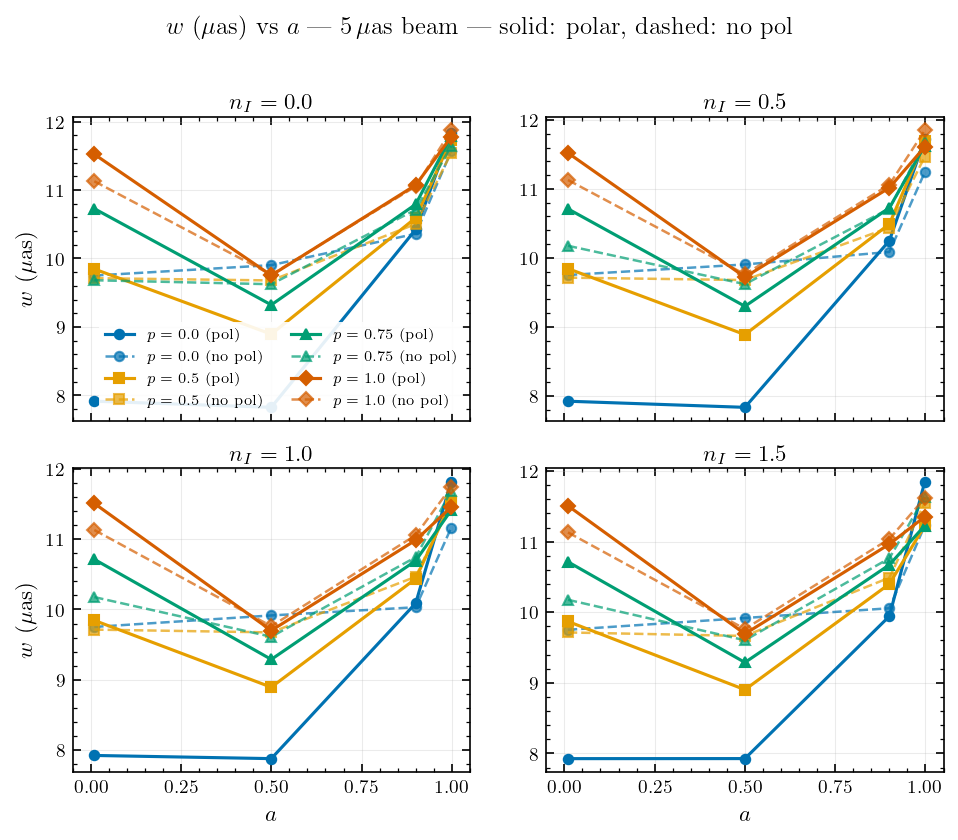

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_vs_spin_by_nI.png


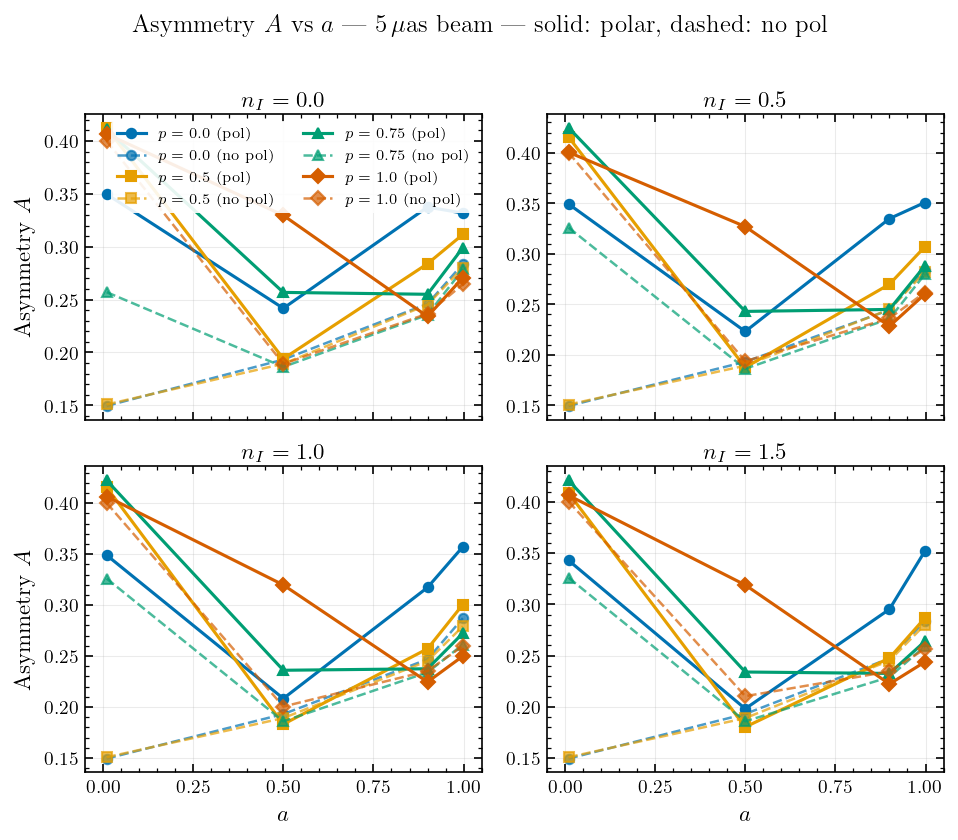

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_vs_spin_by_nI.png


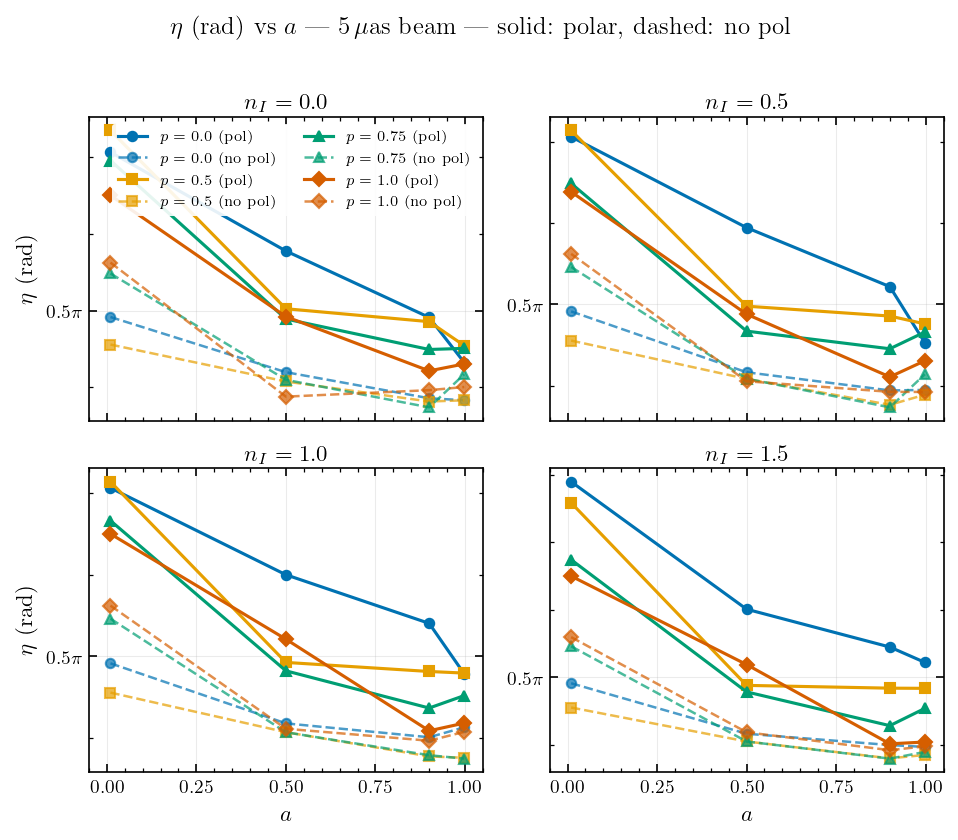

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_vs_spin_by_nI.png


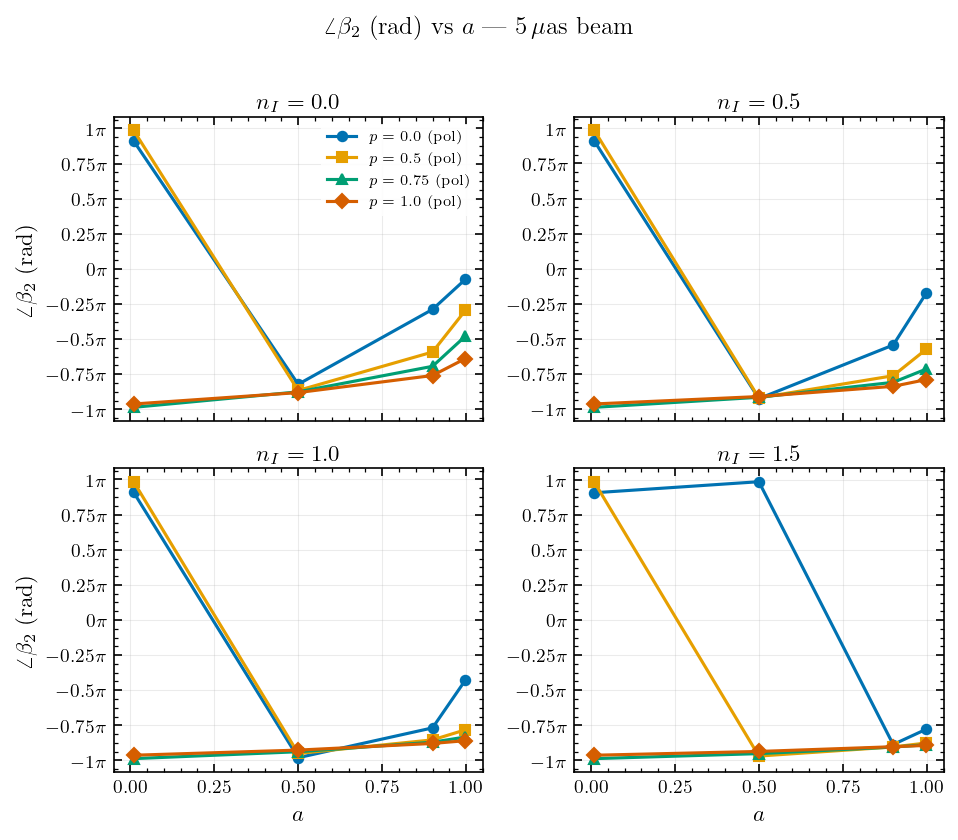

In [30]:
# plot type 3 — observable vs spin
# polar solid, non-polar dashed; 2x2 panels by n_I; lines = p

for obs, meta in all_obs.items():
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.5), sharex=True)
    axes = axes.flatten()

    for ax, n_I in zip(axes, nvals):

        for (p, color, marker) in zip(pvals, COLORS_P, MARKERS):
            d = df_pol[(df_pol['n_I']   == n_I) &
                       (df_pol['p_val'] == p)].sort_values('spin')
            if not d.empty and obs in d.columns:
                ax.plot(d['spin'], d[obs],
                        color=color, marker=marker, lw=1.5, ls='-',
                        label=rf'$p={p}$ (pol)')

            if obs in OBS_SHARED and obs in df_nop.columns:
                d2 = df_nop[(df_nop['n_I']   == n_I) &
                            (df_nop['p_val'] == p)].sort_values('spin')
                if not d2.empty:
                    ax.plot(d2['spin'], d2[obs],
                            color=color, marker=marker, lw=1.2, ls='--',
                            alpha=0.7,
                            label=rf'$p={p}$ (no pol)')

        ax.set_title(rf'$n_I={n_I}$', pad=4)
        ax.set_xlim(-0.05, 1.05)
        ax.set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
        if meta['pi']:
            pi_formatter(ax, scale=4)

    for ax in axes[2:]:
        ax.set_xlabel(r'$a$')
    for ax in [axes[0], axes[2]]:
        ax.set_ylabel(meta['label'])

    handles, labels = axes[0].get_legend_handles_labels()

    axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                   fontsize=7, ncol=2 if obs in OBS_SHARED else 1)

    suffix = ' — solid: polar, dashed: no pol' if obs in OBS_SHARED else ''
    fig.suptitle(
        rf'{meta["label"]} vs $a$ — 5\,$\mu$as beam{suffix}',
        y=1.01
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_vs_spin_by_nI.png')
    plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_summary_all_spins.png


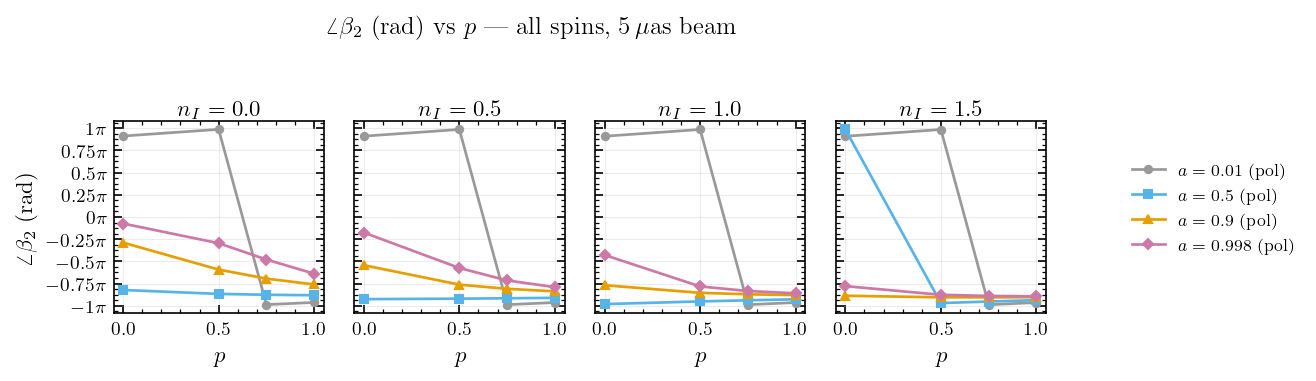

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_summary_all_spins.png


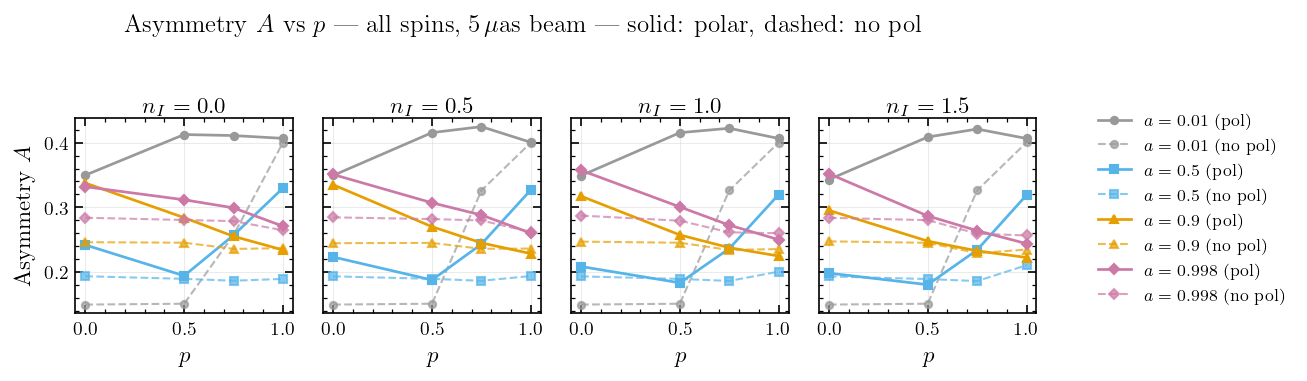

In [31]:
# 1x4 panels by n_I, all spins overlaid
# Asym: polar solid + non-polar dashed on same axes
# argbeta: polar only 

for obs, meta, use_nop in [
    ('argbeta2', OBS_POLAR_ONLY['argbeta2'], False),
    ('Asym',     OBS_SHARED['Asym'],         True),
]:
    fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.4),
                              sharey=True, sharex=True)

    for ax, n_I in zip(axes, nvals):

        for (spin, color, marker) in zip(a_vals, COLORS_A, MARKERS):
            # polar
            d = df_pol[(df_pol['n_I'] == n_I) &
                       (df_pol['spin'] == spin)].sort_values('p_val')
            if not d.empty and obs in d.columns:
                ax.plot(d['p_val'], d[obs],
                        color=color, marker=marker, lw=1.3, ls='-',
                        ms=3.5, label=rf'$a={spin}$ (pol)')

            # non-polar
            if use_nop and obs in df_nop.columns:
                d2 = df_nop[(df_nop['n_I'] == n_I) &
                            (df_nop['spin'] == spin)].sort_values('p_val')
                if not d2.empty:
                    ax.plot(d2['p_val'], d2[obs],
                            color=color, marker=marker, lw=1.0, ls='--',
                            ms=3.5, alpha=0.7,
                            label=rf'$a={spin}$ (no pol)')

        ax.set_title(rf'$n_I={n_I}$', pad=3)
        ax.set_xlabel(r'$p$')
        ax.set_xlim(-0.05, 1.05)
        ax.set_xticks([0.0, 0.5, 1.0])
        if meta['pi']:
            pi_formatter(ax, scale=4)

    axes[0].set_ylabel(meta['label'])

    handles, labels = axes[-1].get_legend_handles_labels()
    fig.legend(handles, labels,
               loc='center right', bbox_to_anchor=(1.22, 0.5),
               framealpha=0.9, edgecolor='none', fontsize=8)

    suffix = ' — solid: polar, dashed: no pol' if use_nop else ''
    fig.suptitle(
        rf'{meta["label"]} vs $p$ — all spins, 5\,$\mu$as beam{suffix}',
        y=1.04
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_summary_all_spins.png')
    plt.show()

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_nI_through_zero.png


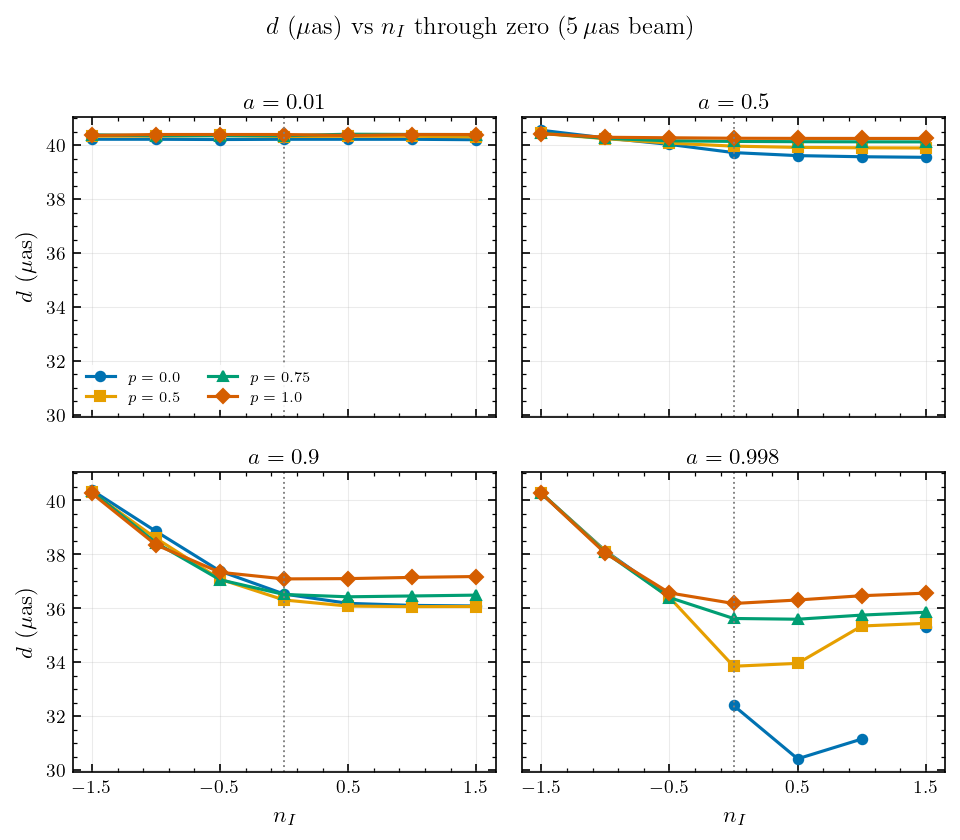

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_nI_through_zero.png


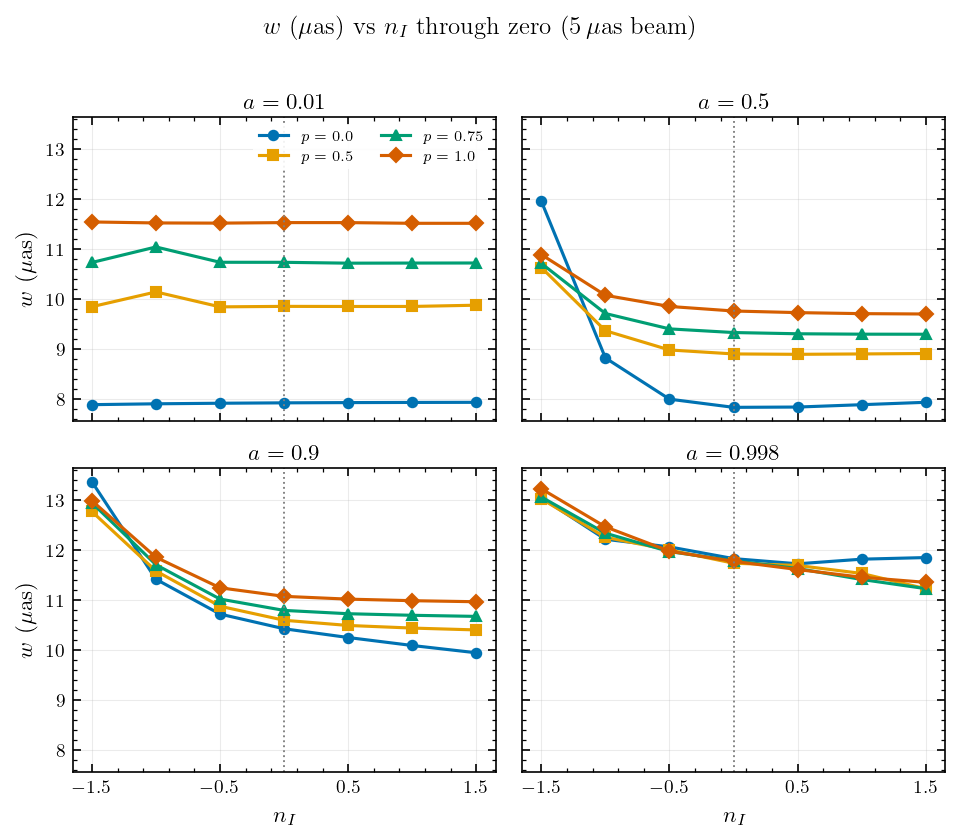

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_nI_through_zero.png


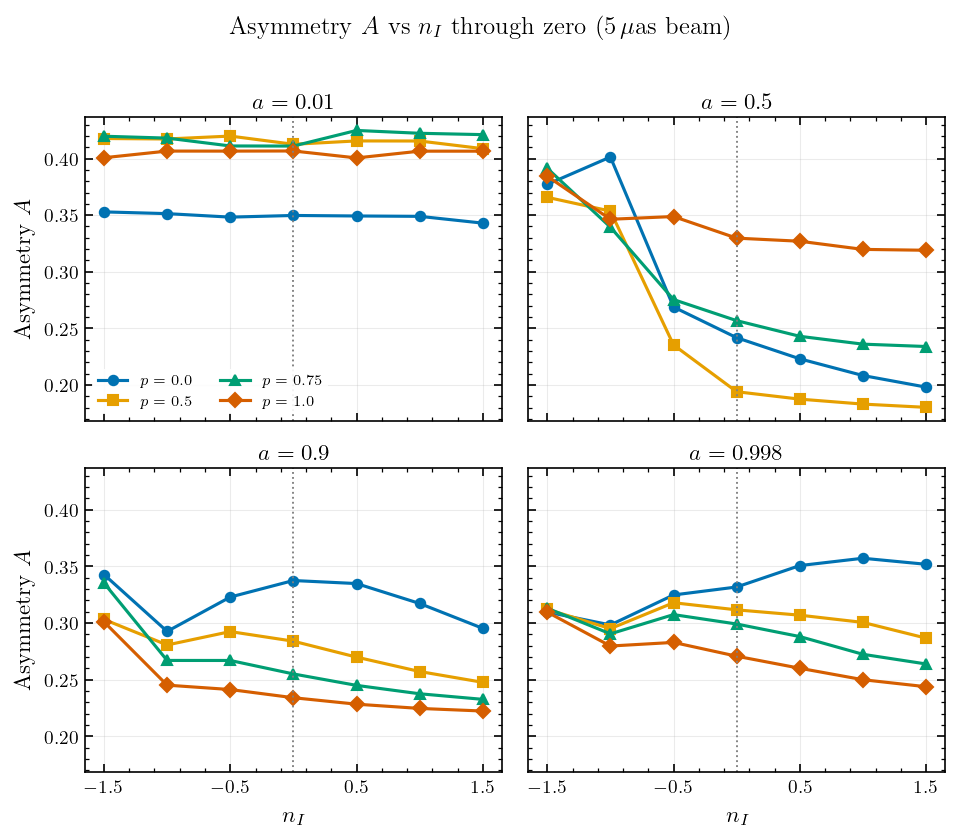

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_nI_through_zero.png


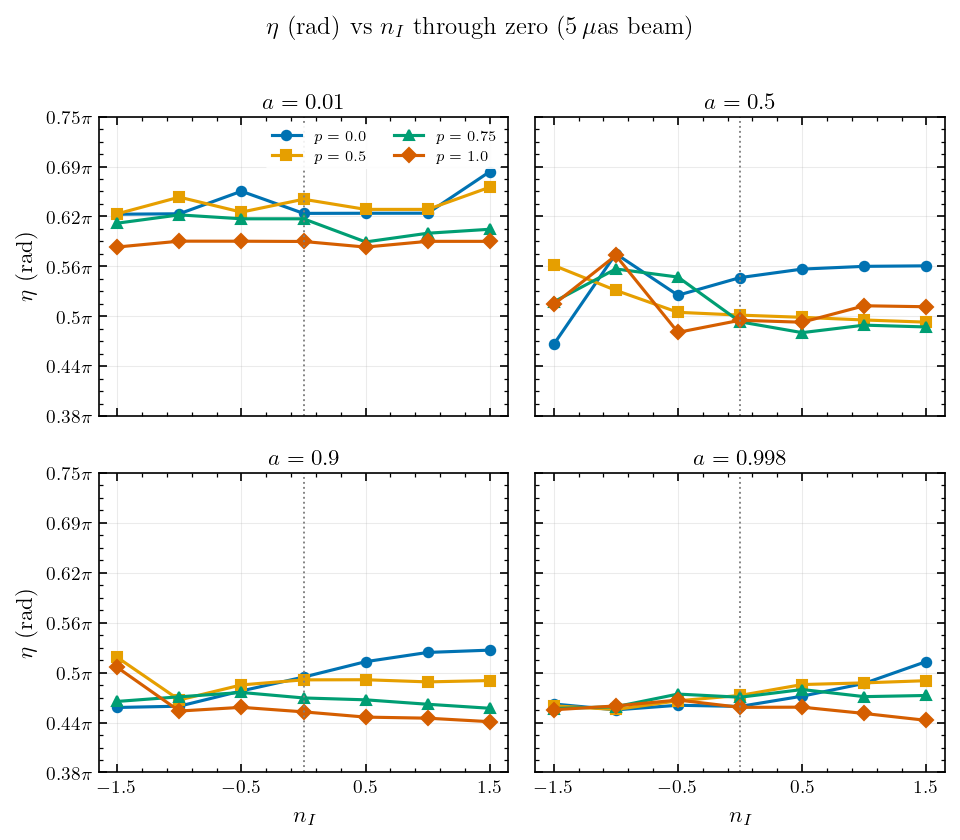

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_nI_through_zero.png


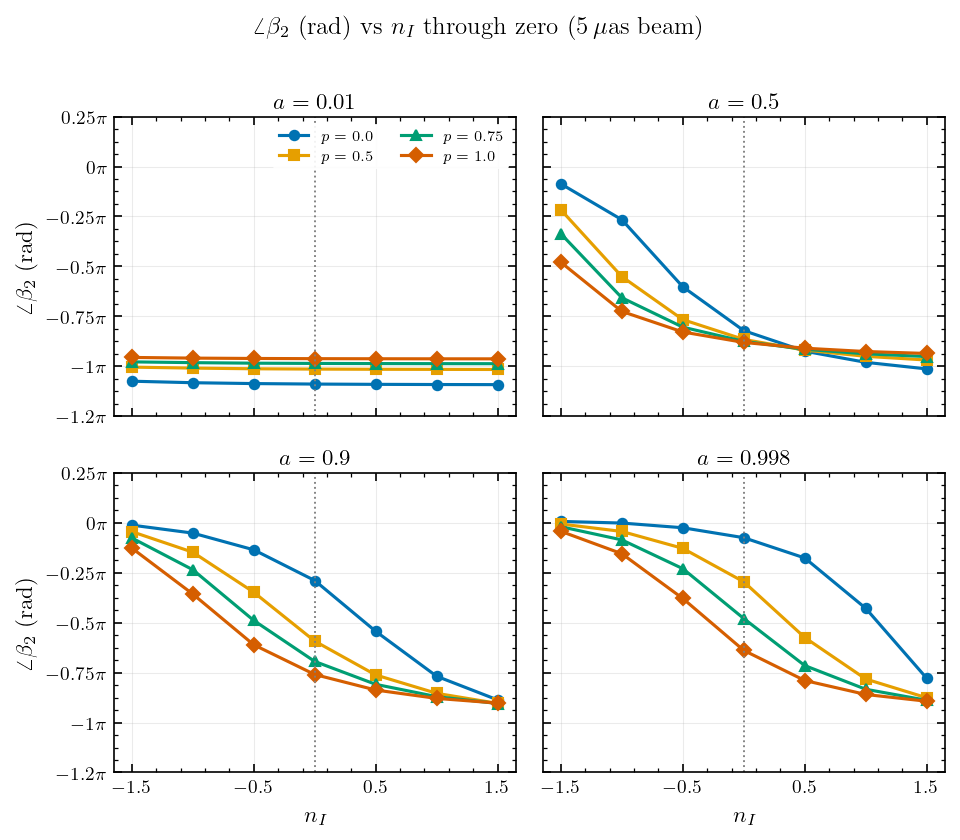

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/d_pm_nI_p0.0.png


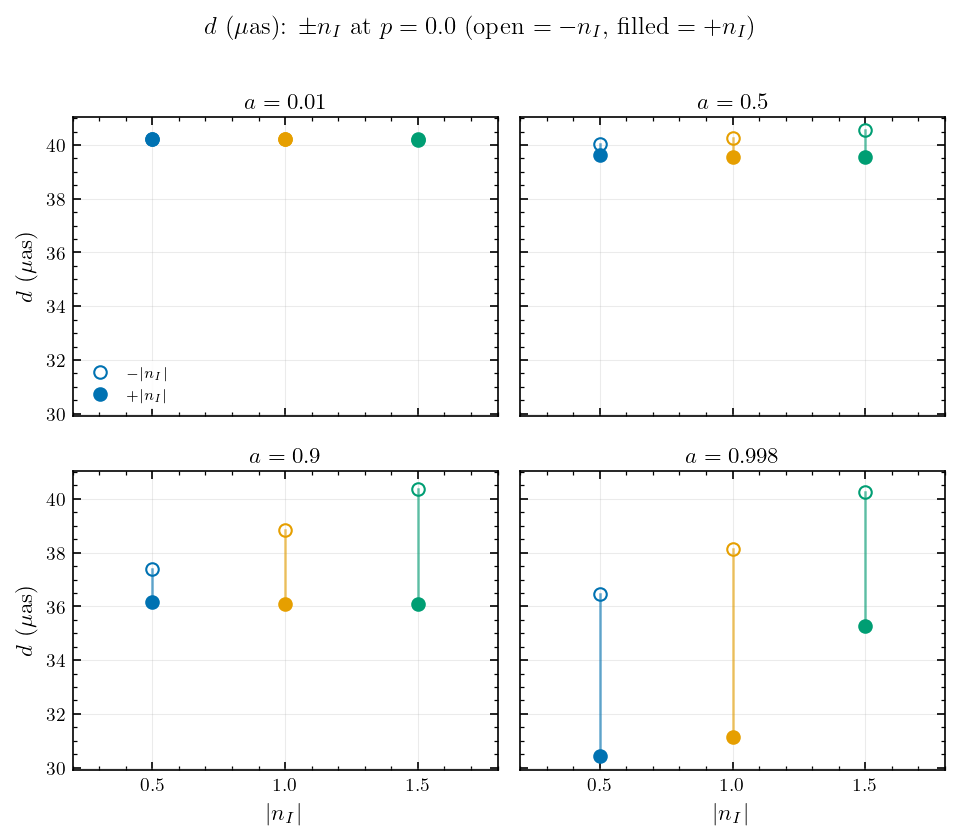

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/w_pm_nI_p0.0.png


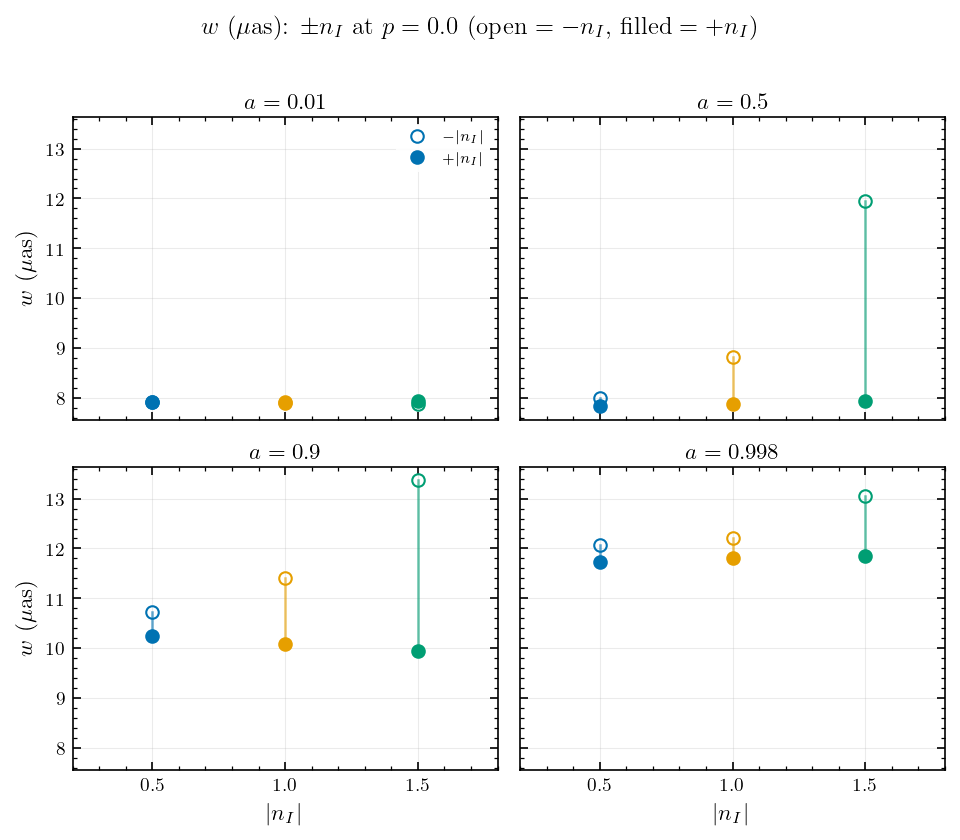

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/Asym_pm_nI_p0.0.png


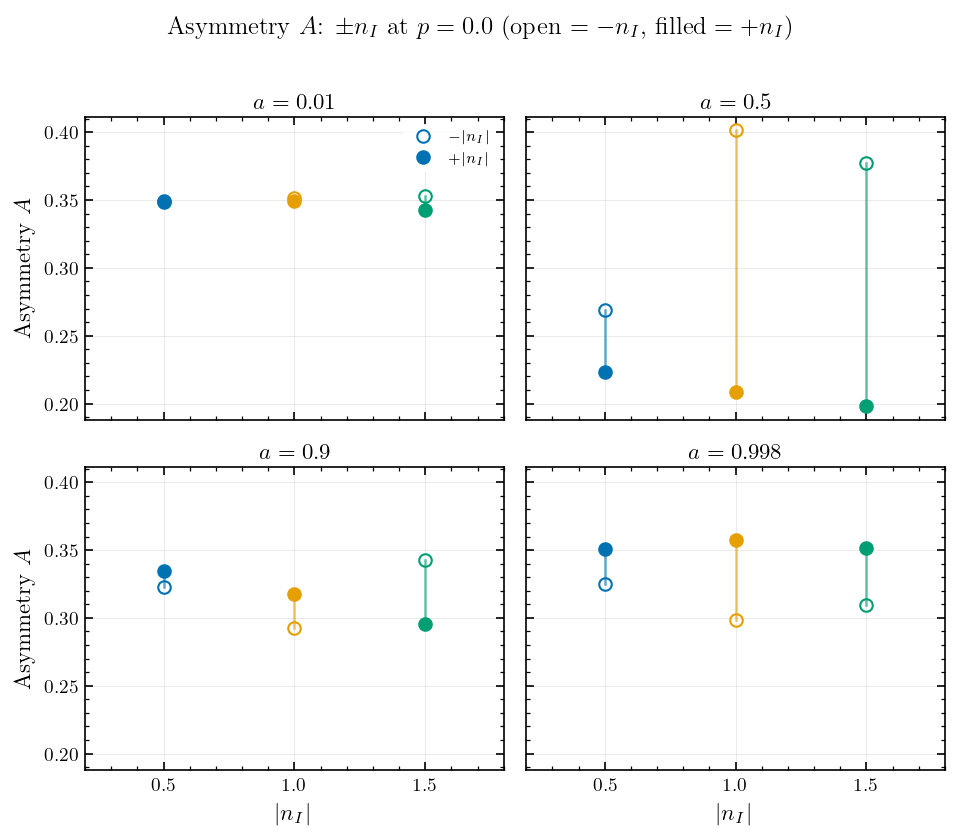

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/eta_pm_nI_p0.0.png


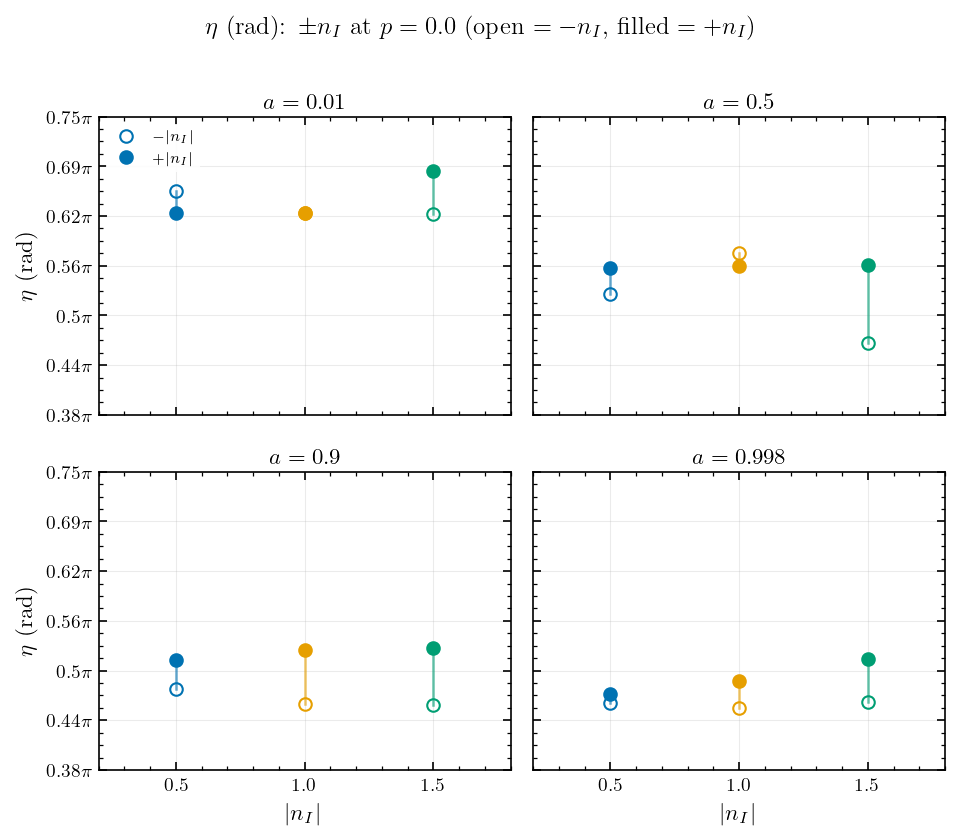

Saved: /Users/kaylacarmical/Documents/JP1/Code/kgeo2/Analysis/argbeta2_pm_nI_p0.0.png


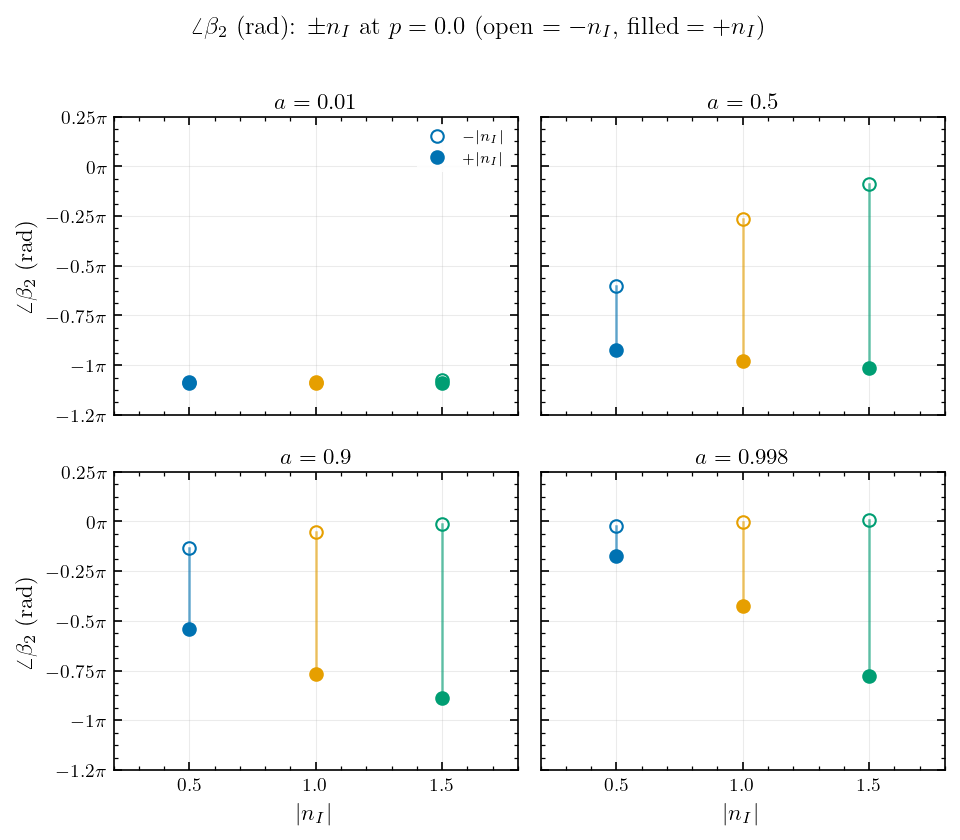

In [32]:
# negative n_I vs fiducial positive

PAIRS = [0.5, 1.0, 1.5]      # |n_I| values to pair (+x vs -x)
P = 0.0                  # fiducial p
COLORS = ['#0072B2', '#E69F00', '#009E73', '#D55E00']
MARKERS = ['o', 's', '^', 'D']

# a — full sweep through zero, one line per p, dotted divide at n_I = 0

for obs, meta in all_obs.items():
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.5),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    if meta['pi']:
        pool = [df_pol[obs].values]
        if obs in OBS_SHARED and obs in df_nop.columns:
            pool.append(df_nop[obs].values)
        pool = np.concatenate(pool)
        lo, hi, wrap = _branch(pool)
    else:
        pool = None
        lo = hi = None
        wrap = lambda z: np.asarray(z, float)

    for ax, spin in zip(axes, a_vals):
        for (p, color, marker) in zip(pvals, COLORS, MARKERS):
            d = df_pol[(df_pol['spin'] == spin) &
                       (df_pol['p_val'] == p)].sort_values('n_I')
            if not d.empty and obs in d.columns:
                _plot(ax, d['n_I'], wrap(d[obs]),
                      color=color, marker=marker, lw=1.5, ls='-',
                      label=rf'$p={p}$')
        ax.axvline(0.0, color='0.5', lw=0.9, ls=':')
        ax.set_title(rf'$a={spin}$', pad=4)
        ax.set_xlim(-1.65, 1.65)
        ax.set_xticks([-1.5, -0.5, 0.5, 1.5])

    if meta['pi'] and lo is not None:
        ylo, yhi, sc = _pi_lims(wrap(pool))
        if meta.get('ylim') is not None:
            ylo, yhi = meta['ylim']
            sc = meta.get('pi_scale', 4)
        for ax in axes:
            pi_formatter(ax, scale=sc)
        axes[0].set_ylim(ylo, yhi)

    for ax in axes[2:]:
        ax.set_xlabel(r'$n_I$')
    for ax in [axes[0], axes[2]]:
        ax.set_ylabel(meta['label'])

    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                   fontsize=7, ncol=2)

    fig.suptitle(
        rf'{meta["label"]} vs $n_I$ through zero  (5\,$\mu$as beam)',
        y=1.01
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_nI_through_zero.png')
    plt.show()

# 3b — matched |n_I| pairing
# x-axis is |n_I|; open markers = -n_I, filled = +n_I, connected per pair

for obs, meta in all_obs.items():
    fig, axes = plt.subplots(2, 2, figsize=(6.5, 5.5),
                             sharex=True, sharey=True)
    axes = axes.flatten()

    if meta['pi']:
        pool = df_pol[obs].values
        lo, hi, wrap = _branch(pool)
    else:
        pool = None
        lo = hi = None
        wrap = lambda z: np.asarray(z, float)

    for ax, spin in zip(axes, a_vals):
        base = df_pol[(df_pol['spin'] == spin) &
                      (df_pol['p_val'] == P)]
        for mag, color in zip(PAIRS, COLORS):
            vals = {}
            for sign in (-1, +1):
                d = base[np.isclose(base['n_I'], sign * mag)]
                if not d.empty and obs in d.columns:
                    vals[sign] = float(wrap(d[obs].values)[0])
            if not vals:
                continue
            if -1 in vals:
                ax.plot([mag], [vals[-1]], color=color, marker='o',
                        mfc='none', ms=6, ls='none',
                        label=rf'$-|n_I|$' if mag == PAIRS[0] else None)
            if +1 in vals:
                ax.plot([mag], [vals[+1]], color=color, marker='o',
                        ms=6, ls='none',
                        label=rf'$+|n_I|$' if mag == PAIRS[0] else None)
            if len(vals) == 2:
                ax.plot([mag, mag], [vals[-1], vals[+1]],
                        color=color, lw=1.2, alpha=0.6)

        ax.set_title(rf'$a={spin}$', pad=4)
        ax.set_xlim(0.2, 1.8)
        ax.set_xticks(PAIRS)

    if meta['pi'] and lo is not None:
        ylo, yhi, sc = _pi_lims(wrap(pool))
        if meta.get('ylim') is not None:
            ylo, yhi = meta['ylim']
            sc = meta.get('pi_scale', 4)
        for ax in axes:
            pi_formatter(ax, scale=sc)
        axes[0].set_ylim(ylo, yhi)

    for ax in axes[2:]:
        ax.set_xlabel(r'$|n_I|$')
    for ax in [axes[0], axes[2]]:
        ax.set_ylabel(meta['label'])

    handles, labels = axes[0].get_legend_handles_labels()
    axes[0].legend(handles, labels, framealpha=0.9, edgecolor='none',
                   fontsize=7, ncol=1)

    fig.suptitle(
        rf'{meta["label"]}: $\pm n_I$ at $p={P}$  '
        rf'(open $=-n_I$, filled $=+n_I$)',
        y=1.01
    )
    fig.tight_layout()
    save_fig(fig, f'{obs}_pm_nI_p{P}.png')
    plt.show()